# Data mining complet — IMS-Rexnord, 2e test (`2nd_test`)
## Maintenance prédictive des roulements — Projet de Fin d'Études

**Jeu de données** : IMS-Rexnord Bearing Data, **Set No. 2**. Quatre roulements Rexnord ZA-2115
montés sur le même arbre (2000 rpm, charge radiale 6000 lbf), un accéléromètre par roulement.
**984 fichiers** d'une seconde chacun (20 480 points échantillonnés à **20 kHz**), acquis toutes
les 10 minutes du **12 au 19 février 2004** (run-to-failure).

**Vérité terrain documentée** : défaillance de la **bague extérieure du Bearing 1 uniquement**
à la fin du test. Les autres roulements n'ont pas défailli.

**Objectif de ce notebook** : reproduire toutes les étapes du pipeline de l'article de référence
sur le 2e test, avec le code, les sorties, les figures et les matrices de confusion :

1. Bibliothèques et configuration
2. Chargement et fusion des données
3. Analyse exploratoire des données (EDA)
4. Extraction de features statistiques
5. Normalisation (z-score)
6. Analyse fréquentielle (FFT, filtres band-pass / high-pass)
7. Transformation en ondelettes (DWT)
8. Labellisation des données (IQR × 1,5)
9. Modèles de machine learning classiques (validation croisée 5-fold)
10. Modèles deep learning : CNN et LSTM
11. Sélection du meilleur modèle et conclusions
12. Inventaire des fichiers produits

## 1. Bibliothèques et configuration

On importe toutes les bibliothèques utilisées dans le notebook :
- **pandas / numpy** : manipulation des données ;
- **matplotlib / seaborn** : figures ;
- **scipy** : statistiques, FFT, filtres de Butterworth ;
- **pywt** : ondelettes discrètes ;
- **scikit-learn** : modèles classiques, validation croisée, métriques ;
- **torch (PyTorch)** : CNN et LSTM (TensorFlow/Keras n'est pas installé dans cet environnement).

Graine aléatoire fixée à 42 pour la reproductibilité.

In [1]:
%matplotlib inline
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
from scipy.stats import zscore
from scipy.fft import fft
from scipy.signal import butter, filtfilt
import pywt
import sklearn
import torch

sns.set(color_codes=True)
np.random.seed(42)

print('numpy        :', np.__version__)
print('pandas       :', pd.__version__)
print('scipy        :', scipy.__version__)
print('scikit-learn :', sklearn.__version__)
print('pywt         :', pywt.__version__)
print('torch        :', torch.__version__)

numpy        : 2.5.2
pandas       : 3.0.3
scipy        : 1.18.0
scikit-learn : 1.7.1
pywt         : 1.8.0
torch        : 2.13.0+cpu


## 2. Chargement et fusion des données

Chaque fichier brut contient 20 480 lignes × 4 colonnes (une colonne par roulement).
Pour chaque fichier, on calcule la **moyenne des valeurs absolues** de chaque colonne :
c'est l'indicateur de vibration moyenne du snapshot. On obtient ainsi une table
**984 lignes × 4 colonnes** (une ligne par fichier, une colonne par roulement).

Le nom du fichier (ex. `2004.02.12.10.32.39`) est converti en index datetime, puis la
table est triée chronologiquement et exportée dans `merged_Dataset_BearingTest_2.csv`.

In [2]:
import os
import pandas as pd
import numpy as np

data_dir = os.environ.get(
    'IMS_2ND_TEST_DIR',
    str(Path.cwd() / 'IMS' / '2nd_test' / '2nd_test'),
)
data_frames = []  # List to store individual DataFrames

for filename in os.listdir(data_dir):
    dataset = pd.read_csv(os.path.join(data_dir, filename), sep='\t')
    dataset_mean_abs = np.array(dataset.abs().mean())
    dataset_mean_abs = pd.DataFrame(dataset_mean_abs.reshape(1, 4))
    dataset_mean_abs.index = [filename]
    data_frames.append(dataset_mean_abs)

# Concatenate the list of DataFrames into a single DataFrame
merged_data = pd.concat(data_frames)

merged_data.columns = ['Bearing 1', 'Bearing 2', 'Bearing 3', 'Bearing 4']

In [3]:
# transform index to datetime format
merged_data.index = pd.to_datetime(merged_data.index, format='%Y.%m.%d.%H.%M.%S')

merged_data = merged_data.sort_index()
merged_data.to_csv('merged_Dataset_BearingTest_2.csv')
merged_data.tail()

,Bearing 1,Bearing 2,Bearing 3,Bearing 4
2004-02-19 05:42:39,0.453335,0.161016,0.137440,0.119047
2004-02-19 05:52:39,0.337583,0.132400,0.144992,0.092125
2004-02-19 06:02:39,0.351111,0.152266,0.151299,0.100817
2004-02-19 06:12:39,0.001857,0.003732,0.003656,0.001786
2004-02-19 06:22:39,0.001168,0.000767,0.000716,0.001699


In [4]:
merged_data.head()

,Bearing 1,Bearing 2,Bearing 3,Bearing 4
2004-02-12 10:32:39,0.058333,0.071832,0.083242,0.043067
2004-02-12 10:42:39,0.058995,0.074006,0.084435,0.044541
2004-02-12 10:52:39,0.060236,0.074227,0.083926,0.044443
2004-02-12 11:02:39,0.061455,0.073844,0.084457,0.045081
2004-02-12 11:12:39,0.061361,0.075609,0.082837,0.045118


**Lecture** : la table couvre 2004-02-12 10:32:39 → 2004-02-19 06:22:39 (984 snapshots).
Les deux dernières lignes ont des vibrations quasi nulles (~0,001) : l'acquisition se termine
après l'arrêt de la machine, consécutif à la défaillance du Bearing 1.

## 3. Analyse exploratoire des données (EDA)

### 3.1 Évolution temporelle des vibrations moyennes

Le tracé des 4 séries montre l'évolution de la vibration moyenne sur les ~7 jours du test.

<Axes: >

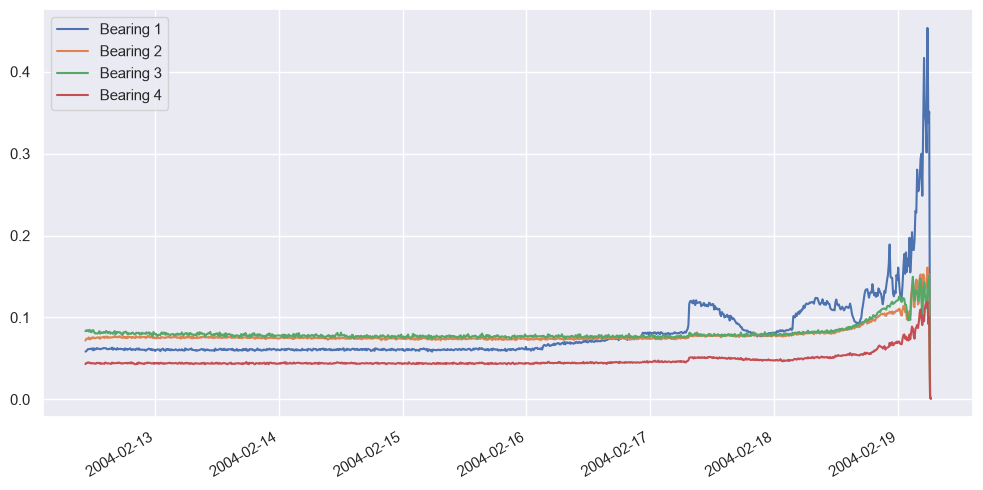

In [5]:
merged_data.plot(figsize = (12, 6))

**Lecture** : le Bearing 1 présente une forte élévation en fin de test (pic à 0,453),
signature de sa dégradation ; les autres roulements restent stables.

### 3.2 Statistiques descriptives

Moyenne, écart-type, minimum et maximum de chaque roulement sur l'ensemble du test.

In [6]:
#Summary statistics of the merged_data
print(np.mean(merged_data, axis=0))
print(np.std(merged_data, axis=0))
print(np.min(merged_data, axis=0))
print(np.max(merged_data, axis=0))

Bearing 1    0.080905
Bearing 2    0.078532
Bearing 3    0.081356
Bearing 4    0.047822
dtype: float64
Bearing 1    0.040151
Bearing 2    0.011773
Bearing 3    0.011590
Bearing 4    0.009536
dtype: float64
Bearing 1    0.001168
Bearing 2    0.000767
Bearing 3    0.000716
Bearing 4    0.001699
dtype: float64
Bearing 1    0.453335
Bearing 2    0.161016
Bearing 3    0.151299
Bearing 4    0.119047
dtype: float64


**Lecture** : Bearing 1 a l'écart-type le plus élevé (0,040 vs ~0,010–0,012) et le
maximum le plus élevé (0,453 vs 0,119–0,161) : c'est le roulement le plus instable.

### 3.3 Tracé comparatif par roulement

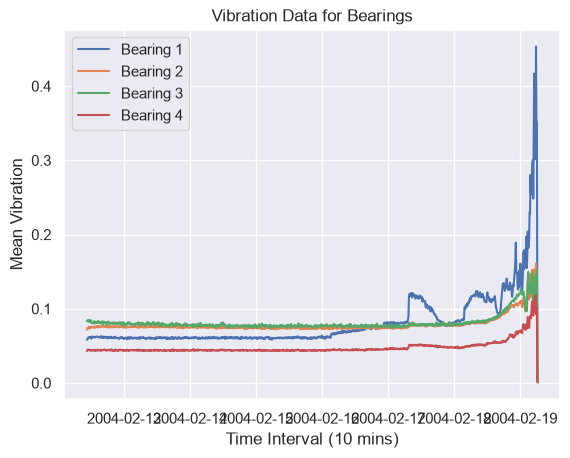

In [7]:
#Plotting the data for vizualization purpose
import matplotlib.pyplot as plt

# Assuming your DataFrame has 4 columns, one for each bearing
for i in range(4):  # Loop through each column (bearing)
    plt.plot(merged_data.iloc[:, i], label=f'Bearing {i + 1}')

plt.xlabel('Time Interval (10 mins)')
plt.ylabel('Mean Vibration')
plt.title('Vibration Data for Bearings')
plt.legend()
plt.show()


### 3.4 Boîtes à moustaches et outliers (z-score)

Le boxplot montre la dispersion et les valeurs extrêmes. On identifie ensuite les
outliers par **z-score** : un snapshot est outlier si |z| > 3 sur au moins un roulement.

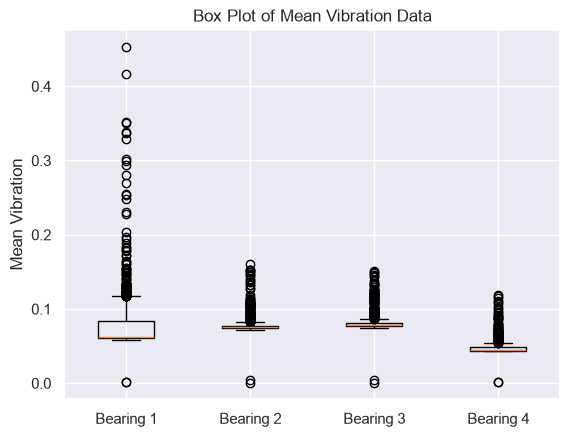

In [8]:
#Box plot to understand the outliers- it is observed that Bearing 1 has the maximum number of outliers
plt.boxplot(merged_data)
plt.xticks([1, 2, 3, 4], ['Bearing 1', 'Bearing 2', 'Bearing 3', 'Bearing 4'])
plt.ylabel('Mean Vibration')
plt.title('Box Plot of Mean Vibration Data')
plt.show()


In [9]:
#outlier identification using z-score
from scipy.stats import zscore

z_scores = np.abs(zscore(merged_data))
outliers = (z_scores > 3).any(axis=1)
print(f"Number of outliers: {np.sum(outliers)}")


Number of outliers: 42


**Résultat** : **42 outliers**. Le boxplot et les statistiques confirment que le
Bearing 1 concentre le plus de valeurs extrêmes.

### 3.5 Histogrammes des vibrations moyennes

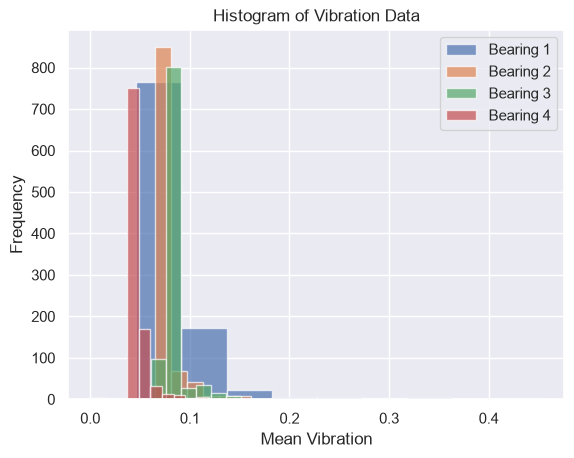

In [10]:
for i in range(4):
    plt.hist(merged_data.iloc[:, i], alpha=0.7, label=f'Bearing {i + 1}')

plt.xlabel('Mean Vibration')
plt.ylabel('Frequency')
plt.title('Histogram of Vibration Data')
plt.legend()
plt.show()


### 3.6 Corrélations entre roulements

Matrice de corrélation de Pearson + heatmap. Les 4 roulements étant sur le même arbre,
ils subissent les mêmes conditions de charge et de vitesse.

In [11]:
#printing the correlation values to understnd how the mean vibration values from each of bearings are corelated
print(merged_data.corr())

           Bearing 1  Bearing 2  Bearing 3  Bearing 4
Bearing 1   1.000000   0.887936   0.807630   0.945133
Bearing 2   0.887936   1.000000   0.965274   0.963396
Bearing 3   0.807630   0.965274   1.000000   0.907867
Bearing 4   0.945133   0.963396   0.907867   1.000000


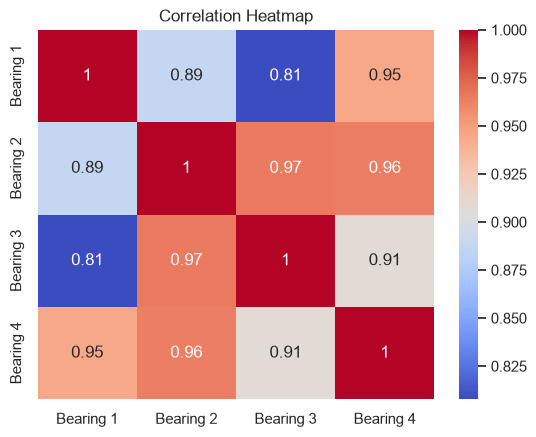

In [12]:
import seaborn as sns

'''
Findings: The strong correlation between bearings 2, 3 & 4 suggests that the vibration pattern of these might be influenced
by similar conditions and we can validate this with other test sets.
'''

sns.heatmap(merged_data.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()


**Lecture** : corrélations fortes (0,81–0,97), surtout entre Bearings 2, 3 et 4
(0,91–0,97) : leurs vibrations évoluent ensemble sous l'effet des conditions communes.

## 4. Extraction de features statistiques

Pour chaque roulement : moyenne, écart-type, **skewness** (asymétrie), **kurtosis**
(aplatissement/queues de distribution), max, min et étendue (range).

In [13]:
#Statistical features for each bearings
'''
Findings: The high skew & kurtosis values of both bearings 1 & 4 indicates that there might be some anomalies in those
bearings a and we should pay close attention to those while analysing further
'''

def extract_statistical_features(df):
    features = pd.DataFrame()
    features['mean'] = merged_data.mean(axis=0)
    features['std'] = merged_data.std(axis=0)
    features['skew'] = merged_data.skew(axis=0)
    features['kurtosis'] = merged_data.kurtosis(axis=0)
    features['max'] = merged_data.max(axis=0)
    features['min'] = merged_data.min(axis=0)
    features['range'] = features['max'] - features['min']
    return features

stat_features = extract_statistical_features(merged_data)
print(stat_features)


               mean       std      skew   kurtosis       max       min  \
Bearing 1  0.080905  0.040171  4.187934  24.727763  0.453335  0.001168   
Bearing 2  0.078532  0.011779  3.106714  19.736684  0.161016  0.000767   
Bearing 3  0.081356  0.011596  2.484647  15.261315  0.151299  0.000716   
Bearing 4  0.047822  0.009541  3.729213  20.338313  0.119047  0.001699   

              range  
Bearing 1  0.452167  
Bearing 2  0.160249  
Bearing 3  0.150583  
Bearing 4  0.117349  


**Lecture** : skew et kurtosis élevés pour **Bearing 1** (4,19 / 24,73) et
**Bearing 4** (3,73 / 20,34) → distributions très asymétriques avec queues lourdes,
indices d'anomalies à surveiller en priorité.

## 5. Normalisation (z-score)

Avant la FFT et les ondelettes, chaque série est centrée-réduite :
`z = (x - moyenne) / écart-type`. Cela rend les 4 roulements comparables
(ils ont des niveaux de vibration différents) et évite qu'un roulement domine
les analyses spectrales purely par son amplitude.

In [14]:
# Normalize the data before applying FFT
# Z-score normalization
merged_data_normalized = merged_data.apply(lambda x: (x - x.mean()) / x.std())

# Then perform FFT as you did earlier


## 6. Analyse fréquentielle (FFT)

### 6.1 Features FFT sur les données normalisées

FFT de chaque série normalisée ; on extrait l'indice du pic de magnitude
(hors composante continue).

In [15]:
#Frequency domain feature extraction
import numpy as np
import pandas as pd
from scipy.fft import fft

# Perform FFT and extract frequency domain features
def extract_frequency_features(df):
    n = merged_data_normalized.shape[0]  # Number of time steps
    fft_features = pd.DataFrame()

    for i in range(merged_data_normalized.shape[1]):  # Loop through each column (bearing)
        # Perform FFT on each bearing's data
        fft_result = fft(merged_data_normalized.iloc[:, i].values)  # Ensure we pass a 1D numpy array
        # Get the magnitude of the FFT coefficients (absolute value)
        magnitude = np.abs(fft_result[:n // 2])  # Only positive frequencies
        peak_frequency = np.argmax(magnitude)  # Find the peak frequency
        fft_features[f'peak_frequency_bearing_{i+1}'] = [peak_frequency]

    return fft_features

# Assuming 'merged_data' is your DataFrame with vibration data
fft_features = extract_frequency_features(merged_data)
print(fft_features)


   peak_frequency_bearing_1  peak_frequency_bearing_2  \
0                         1                         1   

   peak_frequency_bearing_3  peak_frequency_bearing_4  
0                         1                         1  


### 6.2 Fréquences pics sans filtre

Conversion de l'indice du pic en fréquence avec fs = 20 kHz.

**⚠️ Important — artefact de méthode** : cette FFT est appliquée à la table de trend
(984 points espacés de 10 minutes), pas au signal vibratoire intra-fichier échantillonné
à 20 kHz. Le « pic à 20,33 Hz » correspond en réalité à la composante de plus basse
fréquence du trend (fs/n = 20000/984) : c'est un artefact de l'article, pas une
signature physique du roulement. La vraie analyse spectrale à 20 kHz (BPFO, BSF, FTF)
doit être faite intra-fichier — voir `Analyse_Complete_2nd_test.ipynb`, section 4.
On reproduit nevertheless le calcul de l'article pour fidélité.

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.fft import fft

# Define the sampling rate
sampling_rate = 20000  # 20 kHz

# Function to extract peak frequency from each bearing
def extract_peak_frequency(signal, fs):
    n = len(signal)
    # Convert the signal to a NumPy array
    signal = signal.to_numpy()  # Fix for AttributeError
    # Perform FFT
    fft_result = fft(signal)
    # Get the magnitude of the FFT coefficients
    magnitude = np.abs(fft_result[:n // 2])  # Only positive frequencies
    # Find the index of the maximum magnitude (ignoring the DC component)
    peak_index = np.argmax(magnitude[1:]) + 1
    # Convert the index to the actual frequency
    peak_frequency = (peak_index * fs) / n
    return peak_frequency

# Extract peak frequencies for each bearing
peak_frequencies = {}

for i in range(4):  # Loop through each bearing
    signal = merged_data.iloc[:, i]
    peak_frequencies[f'Bearing_{i+1}'] = extract_peak_frequency(signal, sampling_rate)

# Display the peak frequencies
print("Peak Frequencies (in Hz) for Each Bearing:")
print(peak_frequencies)


Peak Frequencies (in Hz) for Each Bearing:
{'Bearing_1': np.float64(20.32520325203252), 'Bearing_2': np.float64(20.32520325203252), 'Bearing_3': np.float64(20.32520325203252), 'Bearing_4': np.float64(20.32520325203252)}


### 6.3 Spectre FFT et filtre band-pass (100–9500 Hz)

Tracé du spectre de magnitude, puis filtrage band-pass de Butterworth (ordre 5)
pour éliminer les très basses et très hautes fréquences, et ré-extraction des pics.

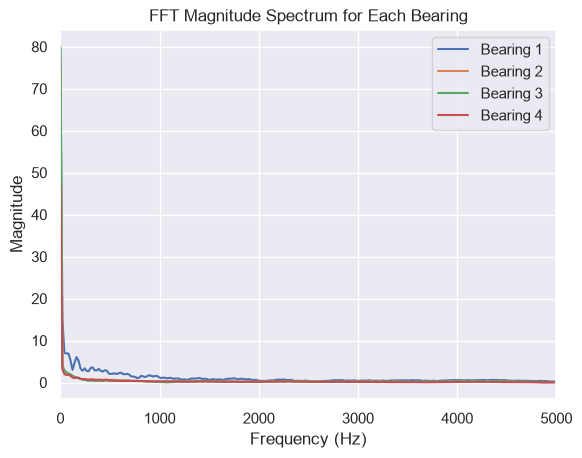

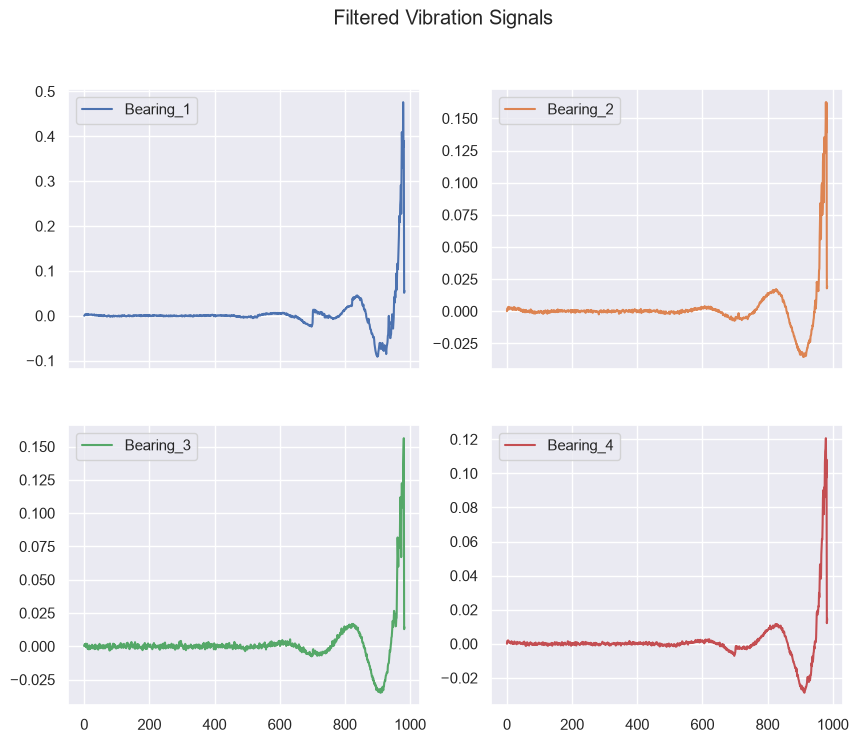

   peak_frequency_bearing_1  peak_frequency_bearing_2  \
0                       0.0                       0.0   

   peak_frequency_bearing_3  peak_frequency_bearing_4  
0                       0.0                       0.0  


In [17]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft

sampling_rate = 20000  # 20 kHz
n = merged_data.shape[0]
frequencies = np.linspace(0, sampling_rate / 2, n // 2)

# Plot FFT magnitude spectrum for each bearing to analyze any low-frequency dominance
for i in range(4):
    signal = merged_data.iloc[:, i].to_numpy()
    fft_result = fft(signal)
    magnitude = np.abs(fft_result[:n // 2])
    plt.plot(frequencies, magnitude, label=f'Bearing {i+1}')

plt.xlabel('Frequency (Hz)')
plt.ylabel('Magnitude')
plt.title('FFT Magnitude Spectrum for Each Bearing')
plt.legend()
plt.xlim(0, 5000)  # Limit to 5 kHz for a closer look
plt.show()


from scipy.signal import butter, filtfilt

# Define the band-pass filter with corrected cutoff values
def bandpass_filter(data, lowcut, highcut, fs, order=5):
    nyquist = 0.5 * fs  # Nyquist frequency (10,000 Hz for 20 kHz sampling rate)
    low = lowcut / nyquist
    high = highcut / nyquist
    if not (0 < low < 1) or not (0 < high < 1):
        raise ValueError(f"Cutoff frequencies must be between 0 and Nyquist frequency ({nyquist} Hz)."
                         f" Received: lowcut={lowcut}, highcut={highcut}")
    b, a = butter(order, [low, high], btype='band')
    return filtfilt(b, a, data)

# Define valid cutoff frequencies
lowcut = 100    # Lower cutoff (e.g., 100 Hz)
highcut = 9500  # Upper cutoff (slightly below Nyquist to avoid boundary issues)
sampling_rate = 20000  # 20 kHz

# Apply the filter
filtered_data = pd.DataFrame()
for i in range(4):
    bearing_data = merged_data.iloc[:, i]
    filtered_data[f'Bearing_{i+1}'] = bandpass_filter(bearing_data, lowcut, highcut, sampling_rate)

# Plot the filtered data
filtered_data.plot(subplots=True, layout=(2, 2), figsize=(10, 8), title='Filtered Vibration Signals')
plt.show()


from scipy.fft import fft

# Perform FFT and extract frequency domain features
def extract_frequency_features(df, sampling_rate):
    n = df.shape[0]  # Number of time steps (samples)
    fft_features = pd.DataFrame()

    for i in range(4):  # Loop through each bearing
        # Convert the column to a NumPy array
        signal = df.iloc[:, i].to_numpy()
        # Perform FFT on each bearing's data
        fft_result = fft(signal)
        # Get the magnitude of the FFT coefficients (absolute value)
        magnitude = np.abs(fft_result[:n // 2])  # Only positive frequencies
        # Calculate the peak frequency index
        peak_frequency_idx = np.argmax(magnitude)
        # Convert peak frequency index to actual frequency in Hz
        peak_frequency = (peak_frequency_idx / n) * sampling_rate
        fft_features[f'peak_frequency_bearing_{i+1}'] = [peak_frequency]

    return fft_features

# Define sampling rate
sampling_rate = 20000  # 20 kHz

# Extract FFT features
fft_features = extract_frequency_features(merged_data, sampling_rate)
print(fft_features)



### 6.4 Variance des données originales

In [18]:
print(merged_data.var())


Bearing 1    0.001614
Bearing 2    0.000139
Bearing 3    0.000134
Bearing 4    0.000091
dtype: float64


**Lecture** : variance du Bearing 1 (0,001614) ~12–18× supérieure à celle des autres
roulements → confirmation quantitative de son instabilité.

### 6.5 Filtre passe-haut (50 Hz) sur les données normalisées

Le passe-haut supprime la composante lente (dérive du trend) ; on trace les signaux
filtrés, leurs spectres, et on extrait les fréquences pics.

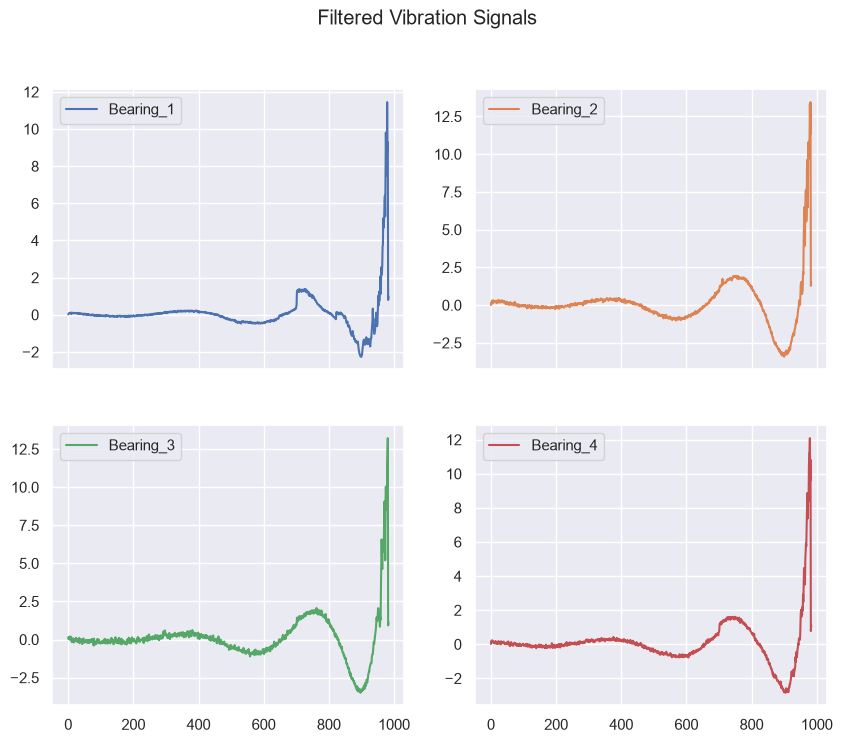

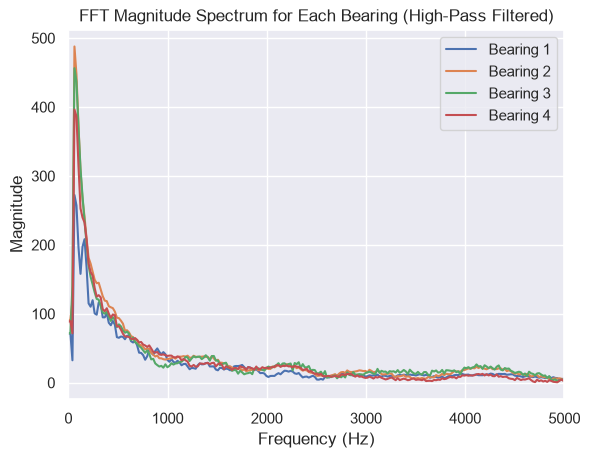

   peak_frequency_bearing_1  peak_frequency_bearing_2  \
0                  60.97561                  60.97561   

   peak_frequency_bearing_3  peak_frequency_bearing_4  
0                  60.97561                  60.97561  


In [19]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft
from scipy.signal import butter, filtfilt

# Define the high-pass filter
def high_pass_filter(data, cutoff_freq, fs, order=5):
    nyquist = 0.5 * fs  # Nyquist frequency (10,000 Hz for 20 kHz sampling rate)
    normal_cutoff = cutoff_freq / nyquist
    b, a = butter(order, normal_cutoff, btype='high', analog=False)
    return filtfilt(b, a, data)

# Define sampling rate and cutoff frequency for high-pass filter
sampling_rate = 20000  # 20 kHz
cutoff_freq = 50  # Set a suitable cutoff frequency (e.g., 50 Hz)

# Apply the high-pass filter to the normalized data (merged_data_normalized)
filtered_data = pd.DataFrame()

# Using the merged_data_normalized instead of merged_data
for i in range(4):
    bearing_data = merged_data_normalized.iloc[:, i]  # Accessing normalized data
    filtered_data[f'Bearing_{i+1}'] = high_pass_filter(bearing_data, cutoff_freq, sampling_rate)

# Plot the filtered data to inspect the results
filtered_data.plot(subplots=True, layout=(2, 2), figsize=(10, 8), title='Filtered Vibration Signals')
plt.show()

# Plot FFT magnitude spectrum for each bearing to analyze any low-frequency dominance
n = filtered_data.shape[0]
frequencies = np.linspace(0, sampling_rate / 2, n // 2)

for i in range(4):
    signal = filtered_data.iloc[:, i].to_numpy()
    fft_result = fft(signal)
    magnitude = np.abs(fft_result[:n // 2])
    plt.plot(frequencies, magnitude, label=f'Bearing {i+1}')

plt.xlabel('Frequency (Hz)')
plt.ylabel('Magnitude')
plt.title('FFT Magnitude Spectrum for Each Bearing (High-Pass Filtered)')
plt.legend()
plt.xlim(0, 5000)  # Limit to 5 kHz for a closer look
plt.show()

# Perform FFT and extract frequency domain features from the filtered data
def extract_frequency_features(df, sampling_rate):
    n = df.shape[0]  # Number of time steps (samples)
    fft_features = pd.DataFrame()

    for i in range(4):  # Loop through each bearing
        # Convert the column to a NumPy array
        signal = df.iloc[:, i].to_numpy()
        # Perform FFT on each bearing's data
        fft_result = fft(signal)
        # Get the magnitude of the FFT coefficients (absolute value)
        magnitude = np.abs(fft_result[:n // 2])  # Only positive frequencies
        # Calculate the peak frequency index
        peak_frequency_idx = np.argmax(magnitude)
        # Convert peak frequency index to actual frequency in Hz
        peak_frequency = (peak_frequency_idx / n) * sampling_rate
        fft_features[f'peak_frequency_bearing_{i+1}'] = [peak_frequency]

    return fft_features

# Extract FFT features from the high-pass filtered data
fft_features = extract_frequency_features(filtered_data, sampling_rate)
print(fft_features)


## 7. Transformation en ondelettes (DWT, db4)

La transformation en ondelettes discrète décompose le signal en coefficients
d'approximation (basses fréquences) et de détail (hautes fréquences). On utilise
l'ondelette de Daubechies `db4`.

### 7.1 Décomposition niveau 4

5 jeux de coefficients (1 approximation + 4 détails) ; on extrait **énergie** et
**moyenne** de chaque jeu, pour chaque roulement.

In [20]:
import pywt
import numpy as np
import pandas as pd

# Assume 'merged_data_normalized' is your DataFrame containing normalized vibration data

def extract_wavelet_features(df):
    wavelet_features = pd.DataFrame()

    for i in range(4):  # Loop through each bearing
        signal = merged_data_normalized.iloc[:, i].to_numpy(copy=True)
        
        # Perform Discrete Wavelet Transform (DWT) - Decompose into 4 levels (can adjust level based on need)
        coeffs = pywt.wavedec(signal, 'db4', level=4)  # 'db4' is Daubechies wavelet with 4 taps
        
        # Extract features from wavelet coefficients (e.g., energy, mean)
        features = []
        for coeff in coeffs:
            energy = np.sum(coeff**2)  # Energy of the wavelet coefficients
            mean = np.mean(coeff)     # Mean of the wavelet coefficients
            features.extend([energy, mean])
        
        # Store features for each bearing
        wavelet_features[f'Bearing_{i+1}_wavelet'] = features

    return wavelet_features

# Extract wavelet features for the normalized data
wavelet_features = extract_wavelet_features(merged_data_normalized)

# Display the extracted features
print(wavelet_features)
wavelet_features

   Bearing_1_wavelet  Bearing_2_wavelet  Bearing_3_wavelet  Bearing_4_wavelet
0         813.486202        1119.232059        1160.361526         958.371345
1          -0.170499          -0.463083          -0.288696          -0.354081
2         176.163273         152.165029         101.749157         217.874132
3          -0.019566          -0.010116          -0.004590          -0.018155
4          60.158826         112.735649          91.991425         123.849268
5           0.005007           0.012638           0.016265           0.005361
6          89.607144         152.541972         189.965418          67.700725
7          -0.001778          -0.013102          -0.002058          -0.005880
8          41.397525          96.052120          95.977653          55.121522
9          -0.002314           0.008439          -0.001000           0.003732


,Bearing_1_wavelet,Bearing_2_wavelet,Bearing_3_wavelet,Bearing_4_wavelet
0,813.486202,1119.232059,1160.361526,958.371345
1,-0.170499,-0.463083,-0.288696,-0.354081
2,176.163273,152.165029,101.749157,217.874132
3,-0.019566,-0.010116,-0.004590,-0.018155
4,60.158826,112.735649,91.991425,123.849268
5,0.005007,0.012638,0.016265,0.005361
6,89.607144,152.541972,189.965418,67.700725
7,-0.001778,-0.013102,-0.002058,-0.005880
8,41.397525,96.052120,95.977653,55.121522
9,-0.002314,0.008439,-0.001000,0.003732


### 7.2 Décomposition niveau 1

Une seule décomposition : le nombre de coefficients est environ divisé par deux
(495 lignes pour 984 points d'entrée).

In [21]:
import numpy as np
import pandas as pd
import pywt  # For wavelet transform

def wavelet_transform(data, wavelet='db4'):
    coeffs = []
    for i in range(data.shape[1]):  # Loop through each bearing
        signal = data.iloc[:, i].to_numpy(copy=True)
        # Perform Discrete Wavelet Transform (DWT)
        coeff, _ = pywt.dwt(signal, wavelet)
        coeffs.append(coeff)  # Store the wavelet coefficients for each bearing

    # Ensure that the result is reshaped correctly to match the number of rows in data
    coeff_df = pd.DataFrame(np.array(coeffs).T, columns=[f'Bearing_{i+1}_wavelet' for i in range(data.shape[1])])
    return coeff_df

# Apply wavelet transform to the normalized data
wavelet_features = wavelet_transform(merged_data_normalized)

# Check the shape of the output
print(wavelet_features.shape)  # Should be (984, 4)

# Display first 20 rows to confirm the result
print(wavelet_features.head(10))  # Should display the first 20 rows, not just 10

(495, 4)
   Bearing_1_wavelet  Bearing_2_wavelet  Bearing_3_wavelet  Bearing_4_wavelet
0          -0.677205          -0.481266           0.281692          -0.425807
1          -0.731222          -0.492694           0.365259          -0.448326
2          -0.796177          -0.790565           0.240381          -0.688228
3          -0.764490          -0.599558           0.348119          -0.541316
4          -0.694703          -0.466147           0.301266          -0.413816
5          -0.677836          -0.547205           0.277077          -0.486987
6          -0.677225          -0.449108           0.205474          -0.551553
7          -0.689774          -0.368005           0.308878          -0.537835
8          -0.700586          -0.450833          -0.040124          -0.625806
9          -0.654936          -0.384237          -0.141164          -0.524287


### 7.3 Features complètes sur les coefficients d'ondelettes

Pour chaque jeu de coefficients : énergie, moyenne, écart-type, skew, kurtosis,
**entropie** (Shannon sur histogramme), max, min, range, RMS — 10 features × 5 niveaux.

In [22]:
'''
Findings: Considering Bearing_4 as an example: The energy values suggest there is a significant variation across the wavelet
scales. However, the entropy values being low suggests periodicity in the signal.
'''


import numpy as np
import pywt
from scipy.stats import skew, kurtosis, entropy
import pandas as pd

def extract_wavelet_features(df):
    # Initialize an empty list to store the feature rows
    all_features = []
    
    # Iterate over each bearing in the DataFrame
    for i in range(4):  # Assuming there are 4 bearings
        signal = df.iloc[:, i].to_numpy(copy=True)  # Get the signal for each bearing
        
        # Perform Discrete Wavelet Transform (DWT)
        coeffs = pywt.wavedec(signal, 'db4', level=4)
        
        # Initialize list to store features for the current bearing
        features = []
        
        for coeff in coeffs:
            # Calculate statistical features for each coefficient set
            energy = np.sum(coeff**2)
            mean = np.mean(coeff)
            std = np.std(coeff)
            sk = skew(coeff)
            kur = kurtosis(coeff)
            ent = entropy(np.histogram(coeff, bins=10, density=True)[0])
            max_val = np.max(coeff)
            min_val = np.min(coeff)
            range_val = max_val - min_val
            rms = np.sqrt(np.mean(coeff**2))
            
            # Store features for the current coefficient set
            features.extend([energy, mean, std, sk, kur, ent, max_val, min_val, range_val, rms])
        
        # Create a row with the feature names and values for the current bearing
        bearing_features = [
            f'Bearing_{i+1}_{feat}' for feat in ['energy', 'mean', 'std', 'skew', 'kurtosis', 'entropy', 
                                                 'max', 'min', 'range', 'rms'] * len(coeffs)
        ]
        
        # Append the features to the list (keeping track of the feature names)
        all_features.append(features)
    
    # Convert the list of features into a DataFrame
    wavelet_features = pd.DataFrame(all_features, columns=bearing_features)
    
    return wavelet_features

# Assuming 'merged_data_normalized' is your DataFrame with the normalized data for the 4 bearings
wavelet_features = extract_wavelet_features(merged_data_normalized)

# Display the extracted features in a tabular format
print(wavelet_features)

   Bearing_4_energy  Bearing_4_mean  Bearing_4_std  Bearing_4_skew  \
0        813.486202       -0.170499       3.454557        3.558772   
1       1119.232059       -0.463083       4.030490        2.657294   
2       1160.361526       -0.288696       4.120776        1.808055   
3        958.371345       -0.354081       3.737422        3.919192   

   Bearing_4_kurtosis  Bearing_4_entropy  Bearing_4_max  Bearing_4_min  \
0           16.887866           0.867902      20.540018      -2.087116   
1           19.304599           0.697948      23.448003     -15.898960   
2           13.397451           0.765784      21.069723     -16.754054   
3           23.855894           0.869145      23.694296     -10.939808   

   Bearing_4_range  Bearing_4_rms  ...  Bearing_4_energy  Bearing_4_mean  \
0        22.627134       3.458762  ...         41.397525       -0.002314   
1        39.346963       4.057006  ...         96.052120        0.008439   
2        37.823776       4.130876  ...         95.

**Lecture** : les énergies varient fortement selon les échelles ; les entropies
faibles indiquent une certaine périodicité du signal. Ces features caractérisent
la texture vibratoire à différentes résolutions temps-fréquence.

## 8. Labellisation des données (IQR × 1,5)

Pour **chaque snapshot et chaque roulement**, on extrait 4 attributs des signaux bruts :
- **RMS** : racine de la moyenne des carrés (temps) ;
- **Energy** : somme des carrés (temps) ;
- **Entropy** : entropie de Shannon normalisée du spectre de puissance (fréquence) ;
- **Kurtosis** : kurtosis de Fisher des amplitudes (temps).

**Règle de labellisation** : pour chaque roulement et chaque attribut, on calcule
Q1, Q3 et IQR = Q3 − Q1. Intervalle accepté : **[Q1 − 1,5×IQR, Q3 + 1,5×IQR]**.
- Label **0 (normal)** : les 4 attributs dans l'intervalle ;
- Label **1 (anomalie)** : au moins un attribut hors intervalle.

⚠️ Ce sont des **labels statistiques**, pas la vérité terrain physique (qui ne
concerne que la bague extérieure du Bearing 1 en fin de test).

In [23]:
from pathlib import Path
from scipy.fft import rfft
from scipy.stats import kurtosis

LABEL_FEATURES = ['rms', 'energy', 'entropy', 'kurtosis']
feature_records = []

for file_path in sorted(Path(data_dir).iterdir()):
    if not file_path.is_file():
        continue

    signals = pd.read_csv(file_path, sep='\t', header=None).to_numpy(dtype=float)
    timestamp = pd.to_datetime(file_path.name, format='%Y.%m.%d.%H.%M.%S')

    for channel, bearing in enumerate(merged_data.columns):
        x = signals[:, channel]
        power_spectrum = np.abs(rfft(x - x.mean()))[1:] ** 2
        power_sum = power_spectrum.sum()

        if power_sum > 0:
            probabilities = power_spectrum / power_sum
            spectral_entropy = float(
                -np.sum(probabilities * np.log(probabilities + np.finfo(float).eps))
                / np.log(probabilities.size)
            )
        else:
            spectral_entropy = 0.0

        feature_records.append({
            'timestamp': timestamp,
            'bearing': bearing,
            'rms': float(np.sqrt(np.mean(x ** 2))),
            'energy': float(np.sum(x ** 2)),
            'entropy': spectral_entropy,
            'kurtosis': float(kurtosis(x, fisher=True, bias=False)),
        })

labelled_features = pd.DataFrame(feature_records).sort_values(['bearing', 'timestamp']).reset_index(drop=True)
print(f'Extracted {len(labelled_features)} bearing-snapshot rows.')
display(labelled_features.head())

Extracted 3936 bearing-snapshot rows.


,timestamp,bearing,rms,energy,entropy,kurtosis
0,2004-02-12 10:32:39,Bearing 1,0.074179,112.691688,0.796238,0.629209
1,2004-02-12 10:42:39,Bearing 1,0.075382,116.377903,0.827574,0.648742
2,2004-02-12 10:52:39,Bearing 1,0.076230,119.008840,0.822986,0.513894
3,2004-02-12 11:02:39,Bearing 1,0.078724,126.923105,0.825564,1.158529
4,2004-02-12 11:12:39,Bearing 1,0.078474,126.120229,0.819868,0.603617


In [24]:
IQR_MULTIPLIER = 1.5
threshold_records = []

for bearing in merged_data.columns:
    bearing_mask = labelled_features['bearing'].eq(bearing)

    for feature in LABEL_FEATURES:
        values = labelled_features.loc[bearing_mask, feature]
        q1, q3 = values.quantile([0.25, 0.75])
        iqr = q3 - q1
        lower_threshold = q1 - IQR_MULTIPLIER * iqr
        upper_threshold = q3 + IQR_MULTIPLIER * iqr

        threshold_records.append({
            'bearing': bearing,
            'feature': feature,
            'q1': q1,
            'q3': q3,
            'iqr': iqr,
            'lower_threshold': lower_threshold,
            'upper_threshold': upper_threshold,
        })

        labelled_features.loc[bearing_mask, f'{feature}_outlier'] = (
            values.lt(lower_threshold) | values.gt(upper_threshold)
        ).astype(int)

iqr_thresholds = pd.DataFrame(threshold_records)
outlier_columns = [f'{feature}_outlier' for feature in LABEL_FEATURES]
labelled_features['outlier_feature_count'] = labelled_features[outlier_columns].sum(axis=1)
labelled_features['label'] = labelled_features['outlier_feature_count'].gt(0).astype(int)

class_distribution = (
    labelled_features.groupby('bearing')['label']
    .value_counts()
    .unstack(fill_value=0)
    .reindex(columns=[0, 1], fill_value=0)
    .rename(columns={0: 'Normal (0)', 1: 'Anomaly (1)'})
)
class_distribution['Total'] = class_distribution.sum(axis=1)
class_distribution['Normal (%)'] = (100 * class_distribution['Normal (0)'] / class_distribution['Total']).round(2)
class_distribution['Anomaly (%)'] = (100 * class_distribution['Anomaly (1)'] / class_distribution['Total']).round(2)

labelled_features.to_csv('bearing_features_labels_2nd_test.csv', index=False)
iqr_thresholds.to_csv('iqr_thresholds_2nd_test.csv', index=False)
class_distribution.to_csv('class_distribution_2nd_test.csv')

print('Class distribution by bearing:')
display(class_distribution)
print('IQR thresholds (multiplier = 1.5):')
display(iqr_thresholds)

Class distribution by bearing:

label,Normal (0),Anomaly (1),Total,Normal (%),Anomaly (%)
bearing,,,,,
Bearing 1,776,208,984,78.86,21.14
Bearing 2,852,132,984,86.59,13.41
Bearing 3,844,140,984,85.77,14.23
Bearing 4,858,126,984,87.20,12.80


IQR thresholds (multiplier = 1.5):


,bearing,feature,q1,q3,iqr,lower_threshold,upper_threshold
0,Bearing 1,rms,0.077137,0.108819,0.031682,0.029613,0.156343
1,Bearing 1,energy,121.857391,242.515705,120.658314,-59.130081,423.503176
2,Bearing 1,entropy,0.754801,0.805284,0.050483,0.679076,0.881009
3,Bearing 1,kurtosis,0.394137,0.879196,0.485059,-0.333452,1.606785
4,Bearing 2,rms,0.093419,0.097358,0.003939,0.087511,0.103266
5,Bearing 2,energy,178.731773,194.120751,15.388978,155.648307,217.204218
6,Bearing 2,entropy,0.768254,0.790468,0.022215,0.734932,0.823790
7,Bearing 2,kurtosis,0.112746,0.206141,0.093395,-0.027346,0.346233
8,Bearing 3,rms,0.099306,0.104180,0.004873,0.091996,0.111490
9,Bearing 3,energy,201.968760,222.277524,20.308764,171.505613,252.740671


**Résultat** : 3 936 lignes labellisées (984 × 4). Distribution des classes :

| Roulement | Normal | Anomalie | % anomalie |
|---|---:|---:|---:|
| Bearing 1 | 776 | 208 | 21,14 % |
| Bearing 2 | 852 | 132 | 13,41 % |
| Bearing 3 | 844 | 140 | 14,23 % |
| Bearing 4 | 858 | 126 | 12,80 % |

Le Bearing 1 a le plus d'anomalies — cohérent avec sa défaillance physique documentée.
Le jeu est **déséquilibré** (84,6 % normal / 15,4 % anomalie au global).

## 9. Modèles de machine learning classiques

### 9.1 Protocole et comparaison de 6 modèles (validation croisée 5-fold)

Objectif : classer chaque snapshot normal (0) / anomalie (1) à partir des 4 attributs.
Six modèles : **Logistic Regression, Decision Tree, Random Forest, SVM (RBF), KNN,
Gaussian Naive Bayes**. Évaluation par **5-fold stratifié par roulement** (pas de simple
train/test split, qui pourrait sur-apprendre). La stratification préserve le ratio
normal/anomalie dans chaque pli ; le scaling est appris dans chaque pli d'entraînement ;
`class_weight='balanced'` quand disponible. Métrique de classement : **F1-score**
(adaptée au déséquilibre), avec accuracy, balanced accuracy, precision, recall, ROC-AUC.

In [25]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score

classical_models = {
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(class_weight='balanced', max_iter=5000, random_state=42)),
    ]),
    'Decision Tree': DecisionTreeClassifier(class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(
        n_estimators=300, class_weight='balanced', random_state=42, n_jobs=-1
    ),
    'SVM (RBF)': Pipeline([
        ('scaler', StandardScaler()),
        ('model', SVC(kernel='rbf', class_weight='balanced', random_state=42)),
    ]),
    'KNN': Pipeline([
        ('scaler', StandardScaler()),
        ('model', KNeighborsClassifier(n_neighbors=5)),
    ]),
    'Gaussian Naive Bayes': GaussianNB(),
}

scoring = {
    'accuracy': 'accuracy',
    'balanced_accuracy': 'balanced_accuracy',
    'precision': make_scorer(precision_score, zero_division=0),
    'recall': make_scorer(recall_score, zero_division=0),
    'f1': make_scorer(f1_score, zero_division=0),
    'roc_auc': 'roc_auc',
}

cv_records = []
for bearing in merged_data.columns:
    bearing_data = labelled_features.loc[labelled_features['bearing'].eq(bearing)]
    X = bearing_data[LABEL_FEATURES]
    y = bearing_data['label']
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    for model_name, model in classical_models.items():
        fold_scores = cross_validate(
            model, X, y, cv=cv, scoring=scoring, n_jobs=1, error_score='raise'
        )
        record = {'bearing': bearing, 'model': model_name}
        for metric in scoring:
            values = fold_scores[f'test_{metric}']
            record[f'{metric}_mean'] = values.mean()
            record[f'{metric}_std'] = values.std()
        cv_records.append(record)

classical_cv_results = pd.DataFrame(cv_records)
print(f'Completed {len(classical_cv_results)} model-bearing evaluations (5 folds each).')

Completed 24 model-bearing evaluations (5 folds each).


Mean cross-validation performance across the four bearings:


,accuracy,balanced_accuracy,precision,recall,f1,roc_auc
model,,,,,,
Decision Tree,0.9970,0.9942,0.9908,0.9902,0.9904,0.9942
Random Forest,0.9964,0.9892,0.9970,0.9791,0.9876,0.9999
KNN,0.9947,0.9833,0.9940,0.9675,0.9802,0.9944
SVM (RBF),0.9883,0.9895,0.9349,0.9912,0.9614,0.9996
Gaussian Naive Bayes,0.9845,0.9651,0.9586,0.9389,0.9466,0.9965
Logistic Regression,0.9787,0.9662,0.9085,0.9491,0.9261,0.9867


F1-score by bearing:


bearing,Bearing 1,Bearing 2,Bearing 3,Bearing 4
model,,,,
Decision Tree,0.9881,0.9811,0.9964,0.9961
Random Forest,0.9928,0.9728,0.9846,1.0000
KNN,0.9952,0.9645,0.9815,0.9794
SVM (RBF),0.9812,0.9398,0.9591,0.9656
Gaussian Naive Bayes,0.9680,0.9363,0.9285,0.9535
Logistic Regression,0.9812,0.8903,0.9263,0.9067


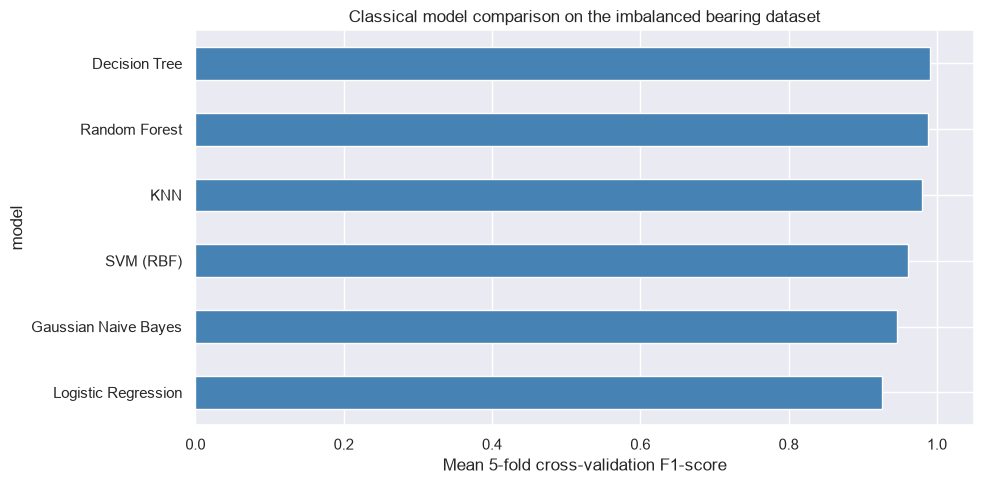

In [26]:
mean_columns = [f'{metric}_mean' for metric in scoring]
classical_cv_summary = (
    classical_cv_results.groupby('model', sort=False)[mean_columns]
    .mean()
    .rename(columns=lambda column: column.removesuffix('_mean'))
    .sort_values('f1', ascending=False)
)

f1_by_bearing = classical_cv_results.pivot(
    index='model', columns='bearing', values='f1_mean'
).reindex(classical_cv_summary.index)

classical_cv_results.to_csv('classical_model_cv_results_2nd_test.csv', index=False)
classical_cv_summary.to_csv('classical_model_cv_summary_2nd_test.csv')

print('Mean cross-validation performance across the four bearings:')
display(classical_cv_summary.round(4))
print('F1-score by bearing:')
display(f1_by_bearing.round(4))

ax = classical_cv_summary['f1'].sort_values().plot.barh(figsize=(10, 5), color='steelblue')
ax.set_xlabel('Mean 5-fold cross-validation F1-score')
ax.set_title('Classical model comparison on the imbalanced bearing dataset')
ax.set_xlim(0, 1.05)
plt.tight_layout()
plt.show()

**Résultat** : le **Decision Tree** domine (F1 moyen = 0,9904), devant Random Forest
(0,9876) et KNN (0,9802). Un modèle simple suffit sur ces données.

⚠️ Ces scores mesurent la reproduction des labels IQR — qui sont dérivés des 4 mêmes
attributs que ceux donnés aux modèles. Les scores quasi parfaits sont donc en partie
mécaniques ; ils ne valident pas la détection de la panne physique réelle.

### 9.2 Les 4 classifieurs de l'article — tests out-of-fold et matrices de confusion

L'article demande **Logistic Regression, Decision Tree, Gaussian Naive Bayes et KNN**.
`cross_val_predict` produit une prédiction out-of-fold par snapshot (même 5-fold
stratifié). On calcule accuracy, precision, recall, F1 et les matrices de confusion
par roulement puis globales (lignes = vrai, colonnes = prédit).

In [27]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

selected_model_names = [
    'Logistic Regression',
    'Decision Tree',
    'Gaussian Naive Bayes',
    'KNN',
]


def get_test_metrics(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred, zero_division=0),
        'recall': recall_score(y_true, y_pred, zero_division=0),
        'f1': f1_score(y_true, y_pred, zero_division=0),
        'tn': int(tn),
        'fp': int(fp),
        'fn': int(fn),
        'tp': int(tp),
    }


test_records = []
pooled_oof_predictions = {
    model_name: {'actual': [], 'predicted': []} for model_name in selected_model_names
}
bearing_confusion_matrices = {}

for bearing in merged_data.columns:
    bearing_data = labelled_features.loc[labelled_features['bearing'].eq(bearing)]
    X = bearing_data[LABEL_FEATURES]
    y = bearing_data['label']
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    for model_name in selected_model_names:
        y_pred = cross_val_predict(
            classical_models[model_name], X, y, cv=cv, method='predict', n_jobs=1
        )
        test_records.append({
            'scope': bearing,
            'model': model_name,
            **get_test_metrics(y, y_pred),
        })
        bearing_confusion_matrices[(model_name, bearing)] = confusion_matrix(
            y, y_pred, labels=[0, 1]
        )
        pooled_oof_predictions[model_name]['actual'].extend(y.to_numpy())
        pooled_oof_predictions[model_name]['predicted'].extend(y_pred)

for model_name in selected_model_names:
    predictions = pooled_oof_predictions[model_name]
    test_records.append({
        'scope': 'Overall',
        'model': model_name,
        **get_test_metrics(predictions['actual'], predictions['predicted']),
    })

selected_model_test_results = pd.DataFrame(test_records)
overall_test_metrics = (
    selected_model_test_results.loc[selected_model_test_results['scope'].eq('Overall')]
    .set_index('model')
    .drop(columns='scope')
    .sort_values('f1', ascending=False)
)
bearing_test_metrics = selected_model_test_results.loc[
    ~selected_model_test_results['scope'].eq('Overall')
].copy()

selected_model_test_results.to_csv('selected_model_test_metrics_2nd_test.csv', index=False)

print('Overall out-of-fold performance (all four bearings):')
display(overall_test_metrics.round(4))
print('Out-of-fold performance and confusion counts by bearing:')
display(bearing_test_metrics.round(4))

Overall out-of-fold performance (all four bearings):


,accuracy,precision,recall,f1,tn,fp,fn,tp
model,,,,,,,,
Decision Tree,0.9970,0.9901,0.9901,0.9901,3324,6,6,600
KNN,0.9947,0.9949,0.9703,0.9825,3327,3,18,588
Gaussian Naive Bayes,0.9845,0.9534,0.9455,0.9495,3302,28,33,573
Logistic Regression,0.9787,0.9117,0.9538,0.9323,3274,56,28,578


Out-of-fold performance and confusion counts by bearing:


,scope,model,accuracy,precision,recall,f1,tn,fp,fn,tp
0,Bearing 1,Logistic Regression,0.9919,0.9717,0.9904,0.9810,770,6,2,206
1,Bearing 1,Decision Tree,0.9949,0.9856,0.9904,0.9880,773,3,2,206
2,Bearing 1,Gaussian Naive Bayes,0.9858,0.9369,1.0000,0.9674,762,14,0,208
3,Bearing 1,KNN,0.9980,1.0000,0.9904,0.9952,776,0,2,206
4,Bearing 2,Logistic Regression,0.9705,0.8931,0.8864,0.8897,838,14,15,117
5,Bearing 2,Decision Tree,0.9949,0.9847,0.9773,0.9810,850,2,3,129
6,Bearing 2,Gaussian Naive Bayes,0.9837,0.9833,0.8939,0.9365,850,2,14,118
7,Bearing 2,KNN,0.9909,0.9920,0.9394,0.9650,851,1,8,124
8,Bearing 3,Logistic Regression,0.9787,0.9103,0.9429,0.9263,831,13,8,132
9,Bearing 3,Decision Tree,0.9990,1.0000,0.9929,0.9964,844,0,1,139


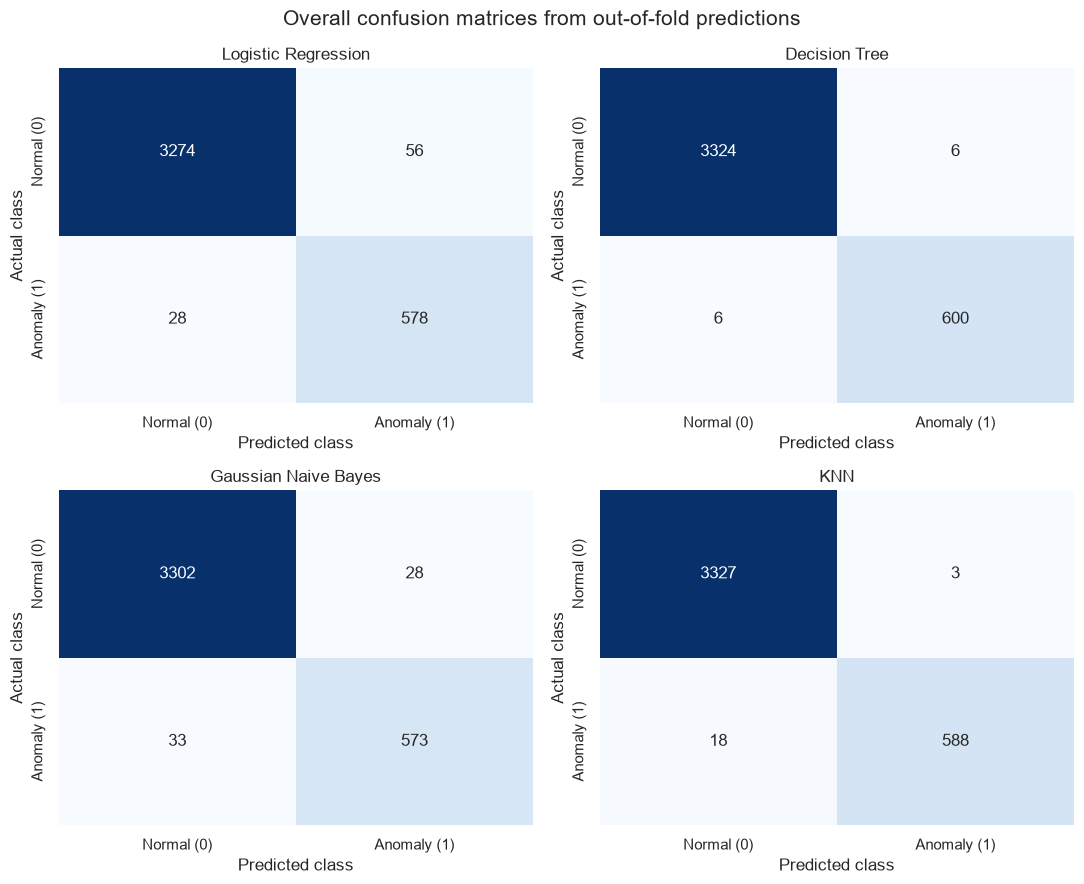

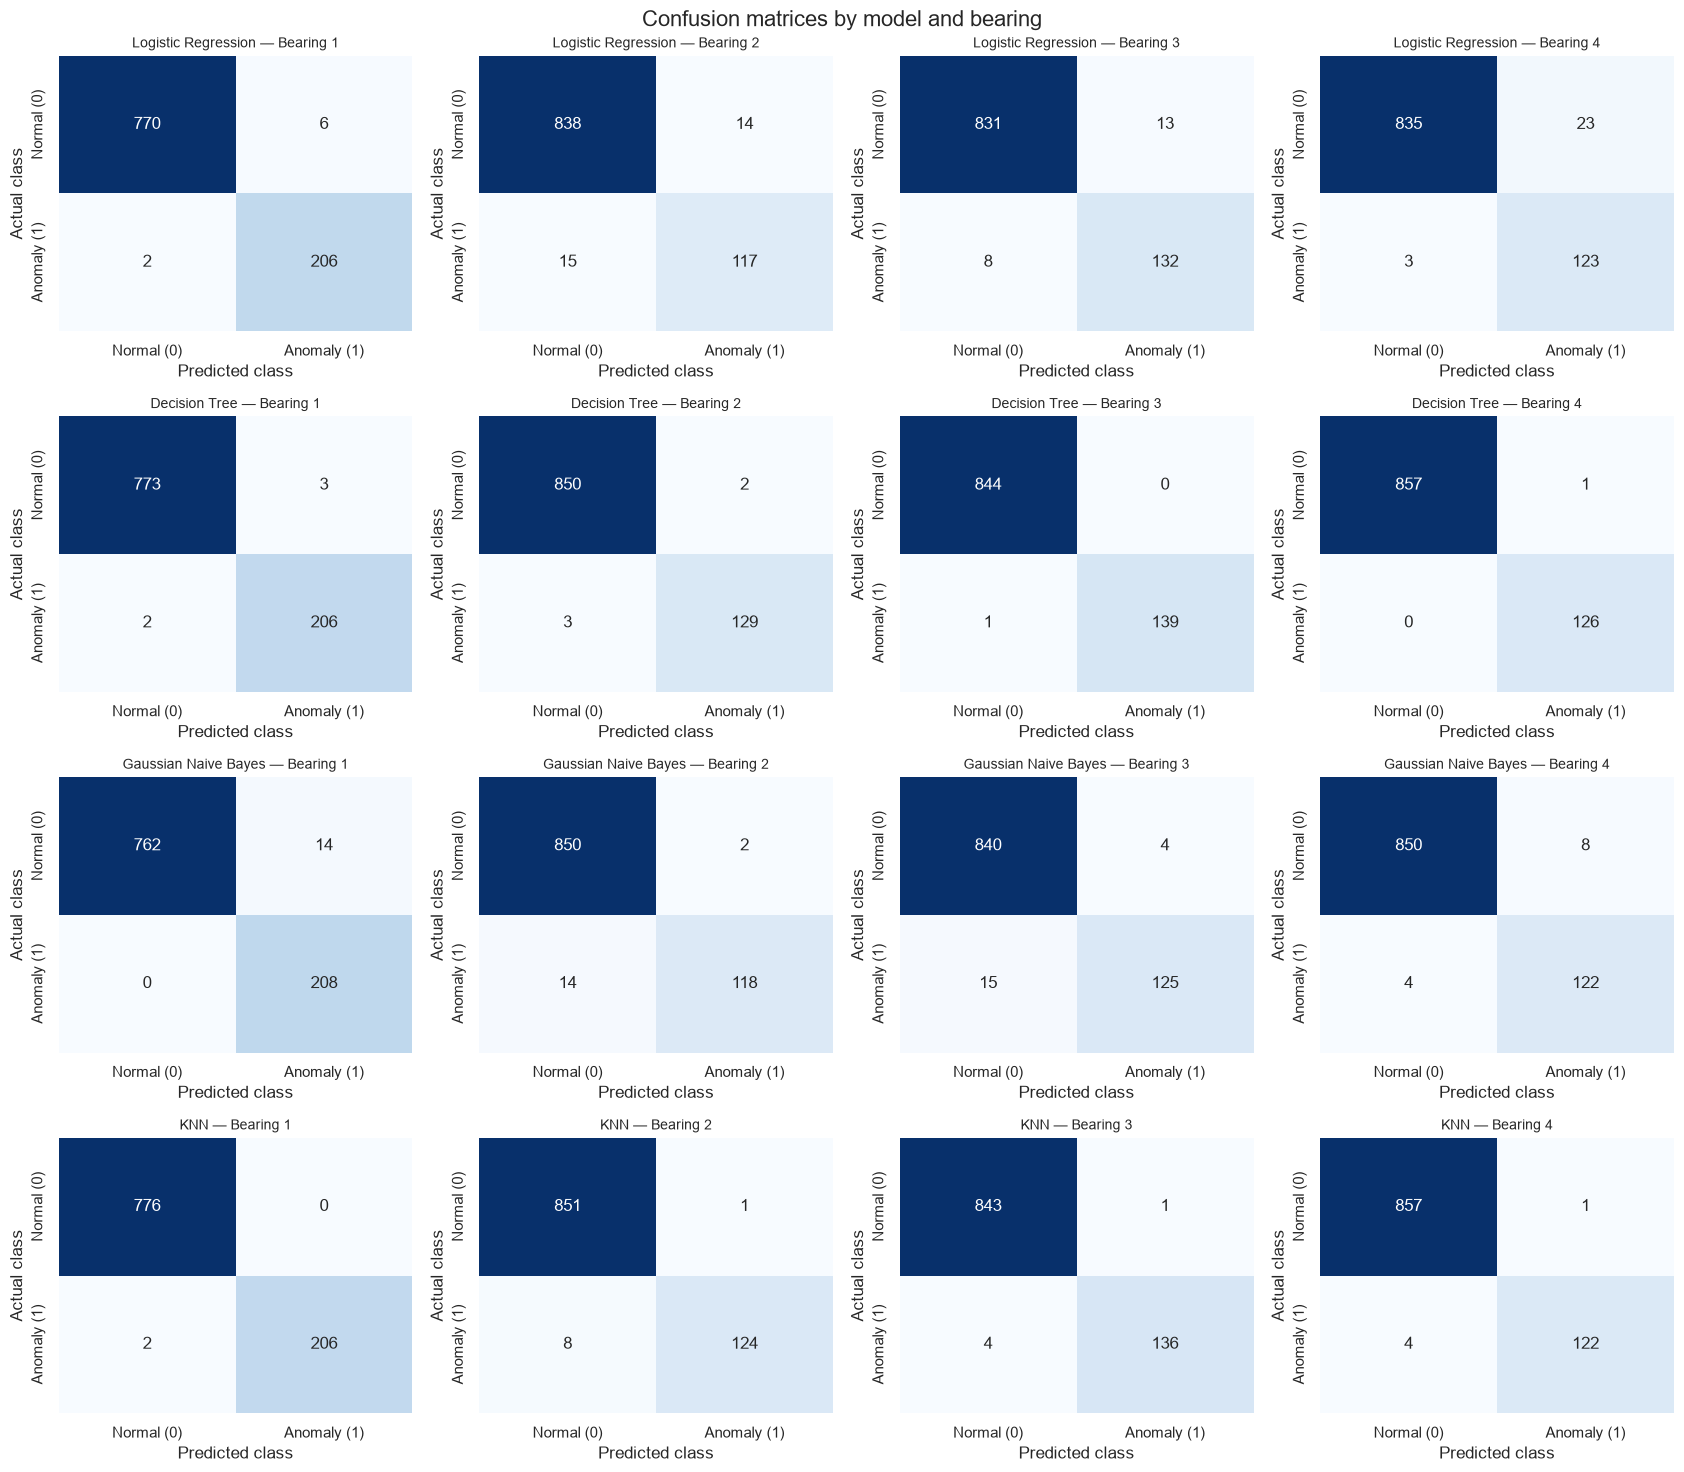

In [28]:
class_labels = ['Normal (0)', 'Anomaly (1)']

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, model_name in zip(axes.flat, selected_model_names):
    predictions = pooled_oof_predictions[model_name]
    cm = confusion_matrix(predictions['actual'], predictions['predicted'], labels=[0, 1])
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues', cbar=False,
        xticklabels=class_labels, yticklabels=class_labels, ax=ax,
    )
    ax.set_title(model_name)
    ax.set_xlabel('Predicted class')
    ax.set_ylabel('Actual class')
fig.suptitle('Overall confusion matrices from out-of-fold predictions', fontsize=15)
plt.tight_layout()
plt.savefig('selected_model_confusion_matrices_2nd_test.png', dpi=150, bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(4, 4, figsize=(17, 15))
for row, model_name in enumerate(selected_model_names):
    for column, bearing in enumerate(merged_data.columns):
        ax = axes[row, column]
        sns.heatmap(
            bearing_confusion_matrices[(model_name, bearing)],
            annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=class_labels, yticklabels=class_labels, ax=ax,
        )
        ax.set_title(f'{model_name} — {bearing}', fontsize=10)
        ax.set_xlabel('Predicted class')
        ax.set_ylabel('Actual class')
fig.suptitle('Confusion matrices by model and bearing', fontsize=16)
plt.tight_layout()
plt.savefig('selected_model_confusion_matrices_by_bearing_2nd_test.png', dpi=150, bbox_inches='tight')
plt.show()

### 9.3 Les 5 modèles demandés — métriques globales et matrices de confusion

Même protocole pour **Decision Tree, SVM (RBF), KNN, Régression logistique,
Random Forest** : prédictions out-of-fold regroupées sur les 4 roulements
(3 936 snapshots : 3 330 normaux / 606 anomalies).

In [29]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

LABEL_FEATURES = ['rms', 'energy', 'entropy', 'kurtosis']
labelled_features = pd.read_csv('bearing_features_labels_2nd_test.csv')
bearings = ['Bearing 1', 'Bearing 2', 'Bearing 3', 'Bearing 4']

requested_models = {
    'Decision Tree': DecisionTreeClassifier(class_weight='balanced', random_state=42),
    'SVM (RBF)': Pipeline([
        ('scaler', StandardScaler()),
        ('model', SVC(kernel='rbf', class_weight='balanced', random_state=42)),
    ]),
    'KNN': Pipeline([
        ('scaler', StandardScaler()),
        ('model', KNeighborsClassifier(n_neighbors=5)),
    ]),
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(class_weight='balanced', max_iter=5000, random_state=42)),
    ]),
    'Random Forest': RandomForestClassifier(
        n_estimators=300, class_weight='balanced', random_state=42, n_jobs=-1
    ),
}

def oof_metrics(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred, zero_division=0),
        'recall': recall_score(y_true, y_pred, zero_division=0),
        'f1': f1_score(y_true, y_pred, zero_division=0),
        'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp),
    }

records = []
pooled = {name: {'actual': [], 'predicted': []} for name in requested_models}

for bearing in bearings:
    bearing_data = labelled_features.loc[labelled_features['bearing'].eq(bearing)]
    X = bearing_data[LABEL_FEATURES]
    y = bearing_data['label']
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    for name, model in requested_models.items():
        y_pred = cross_val_predict(model, X, y, cv=cv, method='predict', n_jobs=1)
        records.append({'scope': bearing, 'model': name, **oof_metrics(y, y_pred)})
        pooled[name]['actual'].extend(y.tolist())
        pooled[name]['predicted'].extend(y_pred.tolist())

overall_cms = {}
for name in requested_models:
    y_true = pooled[name]['actual']
    y_pred = pooled[name]['predicted']
    m = oof_metrics(y_true, y_pred)
    overall_cms[name] = np.array([[m['tn'], m['fp']], [m['fn'], m['tp']]])
    records.append({'scope': 'Overall', 'model': name, **m})

requested5_metrics = pd.DataFrame(records)
requested5_metrics.to_csv('requested5_models_oof_metrics_2nd_test.csv', index=False)

overall_table = requested5_metrics.loc[requested5_metrics['scope'].eq('Overall')].set_index('model')
print('Global out-of-fold metrics (5-fold stratified CV per bearing, pooled over 4 bearings):')
display(overall_table[['accuracy', 'precision', 'recall', 'f1']].round(4))
print('Per-bearing metrics saved to requested5_models_oof_metrics_2nd_test.csv')

Global out-of-fold metrics (5-fold stratified CV per bearing, pooled over 4 bearings):


,accuracy,precision,recall,f1
model,,,,
Decision Tree,0.9970,0.9901,0.9901,0.9901
SVM (RBF),0.9883,0.9361,0.9917,0.9631
KNN,0.9947,0.9949,0.9703,0.9825
Logistic Regression,0.9787,0.9117,0.9538,0.9323
Random Forest,0.9964,0.9966,0.9802,0.9884


Per-bearing metrics saved to requested5_models_oof_metrics_2nd_test.csv


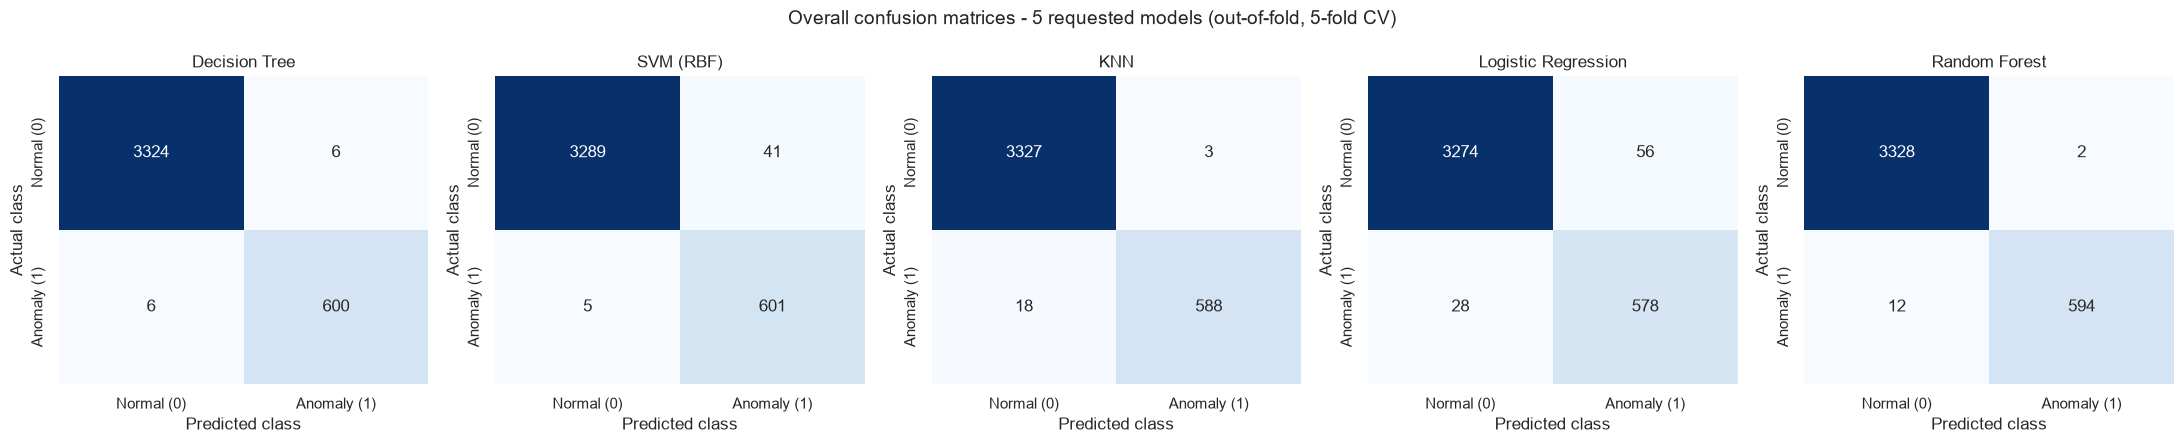

In [30]:
class_labels = ['Normal (0)', 'Anomaly (1)']
fig, axes = plt.subplots(1, 5, figsize=(22, 4.5))
for ax, name in zip(axes, requested_models):
    sns.heatmap(
        overall_cms[name], annot=True, fmt='d', cmap='Blues', cbar=False,
        xticklabels=class_labels, yticklabels=class_labels, ax=ax,
    )
    ax.set_title(name)
    ax.set_xlabel('Predicted class')
    ax.set_ylabel('Actual class')
fig.suptitle('Overall confusion matrices - 5 requested models (out-of-fold, 5-fold CV)', fontsize=14)
plt.tight_layout()
plt.savefig('requested5_confusion_matrices_2nd_test.png', dpi=150, bbox_inches='tight')
plt.show()

**Résultat global** : Decision Tree F1 = **0,9901** (6 FP / 6 FN), Random Forest
F1 = 0,9884, KNN 0,9825, SVM 0,9631 (41 FP), Régression logistique 0,9323 (56 FP / 28 FN).

### 9.4 Matrices de confusion par roulement (5 modèles × 4 roulements)

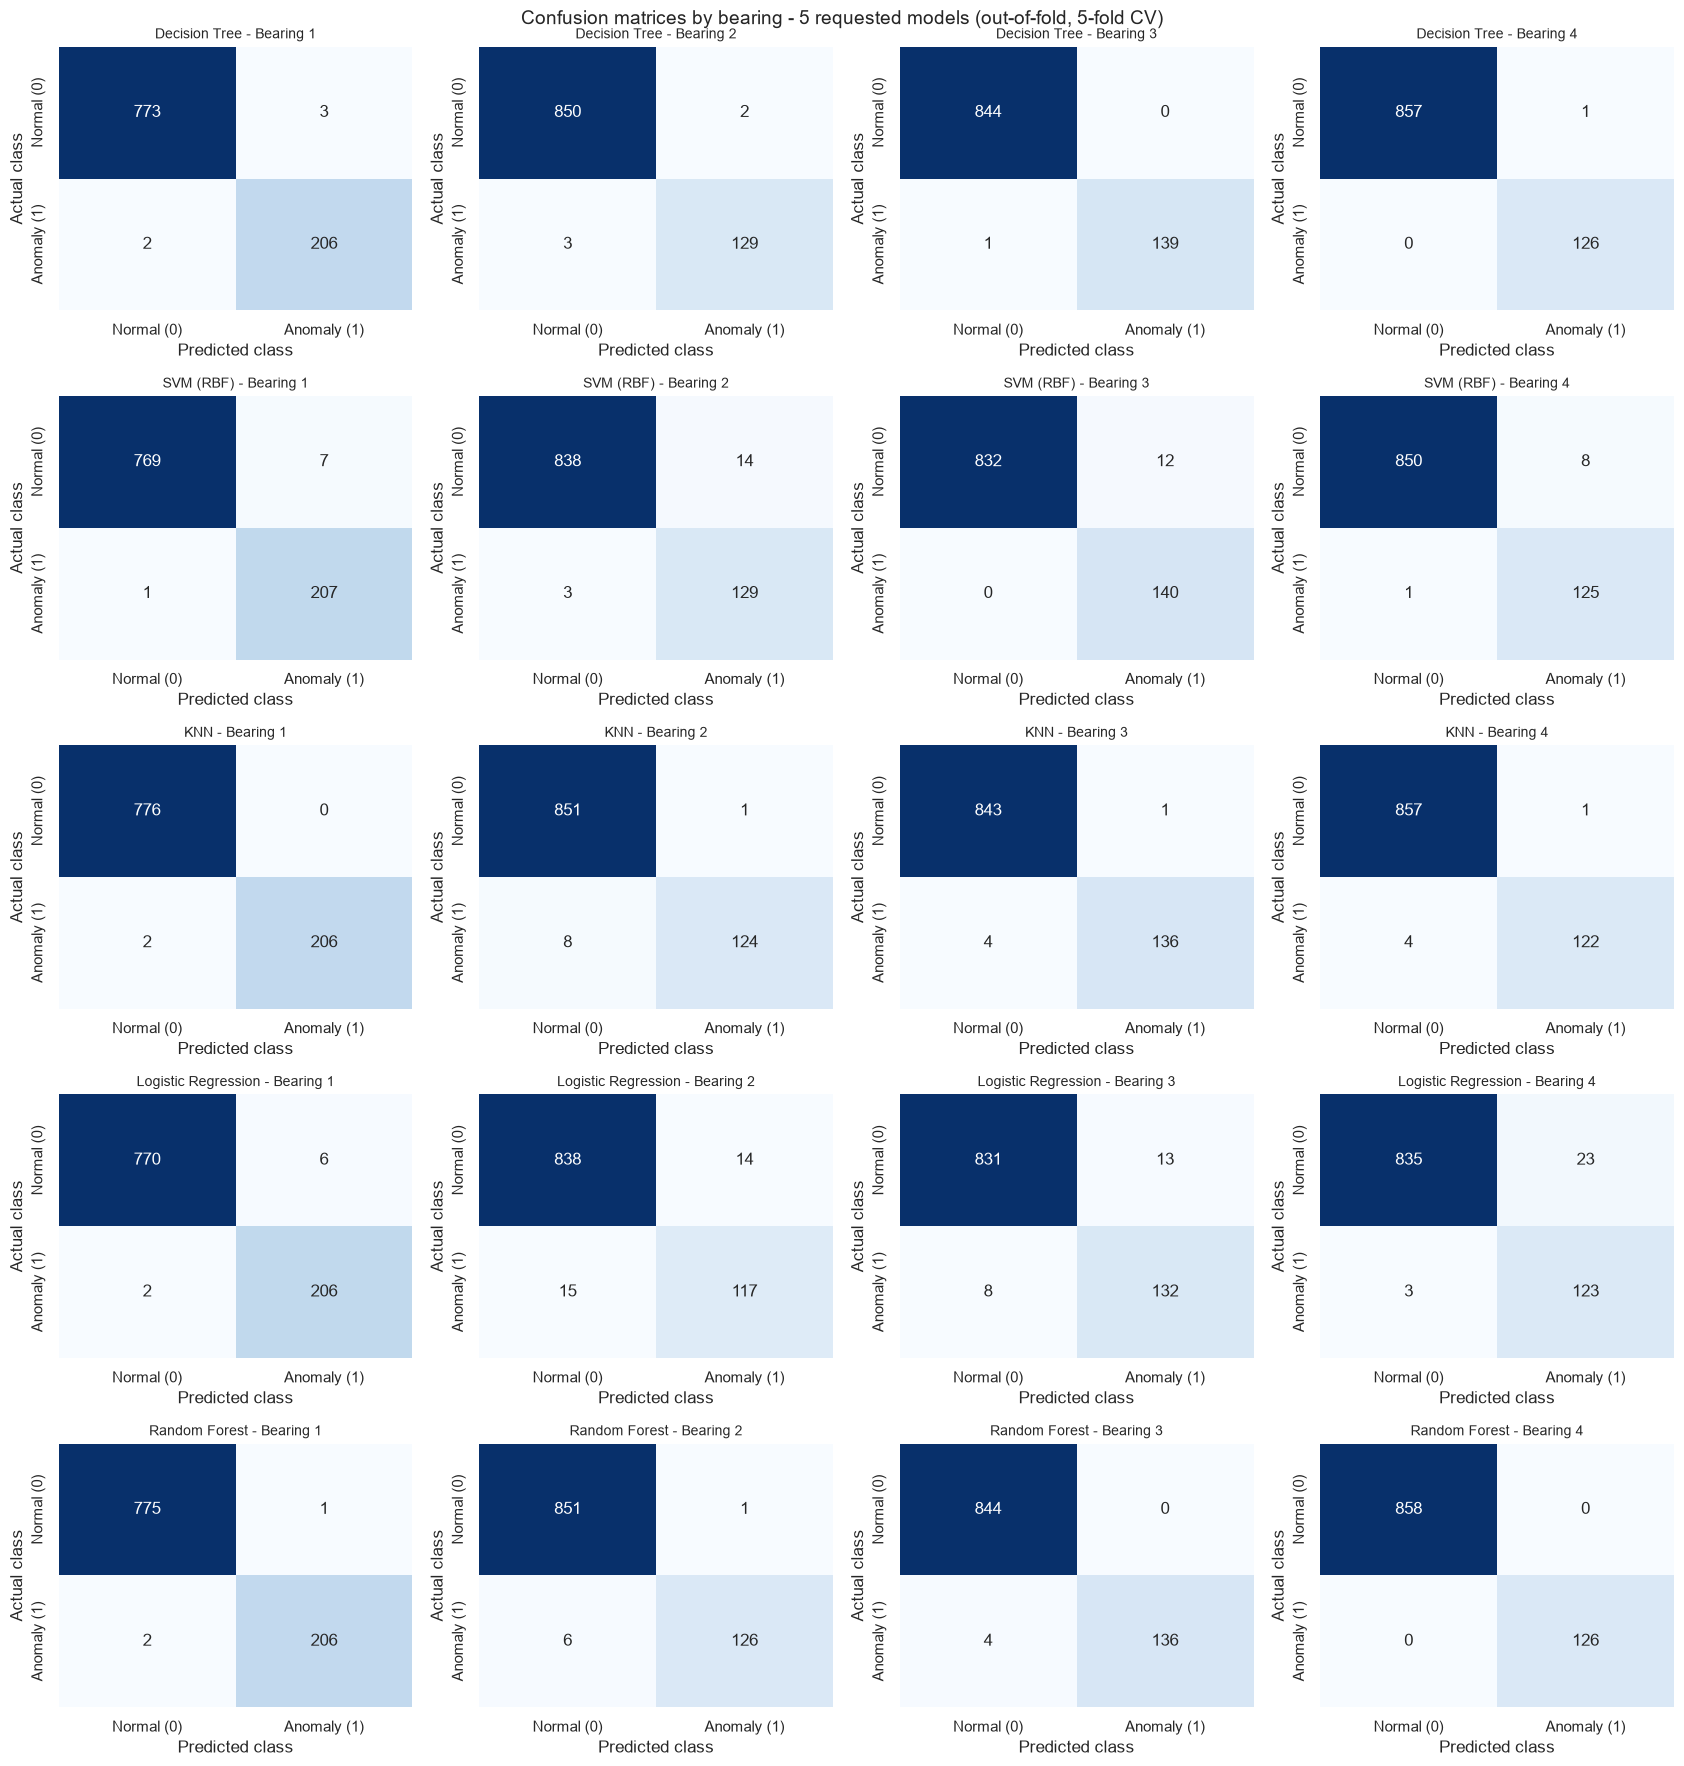

In [31]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

metrics5 = pd.read_csv('requested5_models_oof_metrics_2nd_test.csv')
model_names = ['Decision Tree', 'SVM (RBF)', 'KNN', 'Logistic Regression', 'Random Forest']
bearing_names = ['Bearing 1', 'Bearing 2', 'Bearing 3', 'Bearing 4']
class_labels = ['Normal (0)', 'Anomaly (1)']

fig, axes = plt.subplots(5, 4, figsize=(17, 18))
for row, name in enumerate(model_names):
    for col, bearing in enumerate(bearing_names):
        r = metrics5.loc[metrics5['scope'].eq(bearing) & metrics5['model'].eq(name)].iloc[0]
        cm = np.array([[r['tn'], r['fp']], [r['fn'], r['tp']]])
        ax = axes[row, col]
        sns.heatmap(
            cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=class_labels, yticklabels=class_labels, ax=ax,
        )
        ax.set_title(f'{name} - {bearing}', fontsize=10)
        ax.set_xlabel('Predicted class')
        ax.set_ylabel('Actual class')
fig.suptitle('Confusion matrices by bearing - 5 requested models (out-of-fold, 5-fold CV)', fontsize=14)
plt.tight_layout()
plt.savefig('requested5_confusion_matrices_by_bearing_2nd_test.png', dpi=150, bbox_inches='tight')
plt.show()

**Lecture** : Bearing 1 est le mieux classé (KNN : 0 FP). Bearing 2 est le plus dur
pour la régression logistique et SVM (14 FP chacun). Random Forest est parfait sur
Bearing 4 (0 FP, 0 FN).

### 9.6 Entrainement sur les 4 roulements du 2nd_test, test sur B3 du 1st_test

Protocole demande : entrainer sur B1, B2, B3 et B4 du `2nd_test`, puis evaluer uniquement B3 du `1st_test`. Le 1st_test enregistre deux voies (axes x/y) par roulement alors que le 2nd_test enregistre une voie. Pour B3, on calcule les quatre features sur chaque voie, puis on en prend la moyenne pour obtenir une ligne par snapshot. Ce decalage de capteur limite la comparabilite et doit etre signale. Les labels sont des pseudo-labels IQR : seuils appris sur les 4 roulements du train pour etiqueter le train; pour la reference externe B3, le seuil est appris sur les seules donnees B3 du 2nd_test, sans consulter les features du test B3.

Cette evaluation est distincte du test leave-one-bearing-out precedent : ici B3 du 2nd_test participe bien a l'entrainement. Les metriques mesurent l'accord avec ces pseudo-labels, pas une verite terrain de panne.

In [1]:
from pathlib import Path
from scipy.fft import rfft
from scipy.stats import kurtosis

all_train_test_root = Path(data_dir).parent.parent
first_test_candidates_all_train = [
    all_train_test_root / '1st_test' / '1st_test',
    all_train_test_root / '1st_test',
]
FIRST_TEST_DIR_ALL_TRAIN = next(
    (candidate for candidate in first_test_candidates_all_train
     if candidate.is_dir() and any(p.is_file() and not p.name.startswith('.') for p in candidate.iterdir())),
    None,
)
if FIRST_TEST_DIR_ALL_TRAIN is None:
    raise FileNotFoundError(
        '1st_test data not found. Extract IMS/1st_test.rar beside 2nd_test, '
        'or set FIRST_TEST_DIR_ALL_TRAIN to the folder containing timestamped files.'
    )

B3_CHANNELS_1ST_TEST = (4, 5)
first_test_paths_all_train = sorted(
    p for p in FIRST_TEST_DIR_ALL_TRAIN.iterdir()
    if p.is_file() and not p.name.startswith('.')
)
if not first_test_paths_all_train:
    raise ValueError(f'No timestamped data files found in {FIRST_TEST_DIR_ALL_TRAIN}.')


def _b3_test_features_from_axis(x):
    power_spectrum = np.abs(rfft(x - x.mean()))[1:] ** 2
    power_sum = power_spectrum.sum()
    if power_sum > 0:
        probabilities = power_spectrum / power_sum
        entropy = float(
            -np.sum(probabilities * np.log(probabilities + np.finfo(float).eps))
            / np.log(probabilities.size)
        )
    else:
        entropy = 0.0
    return {
        'rms': float(np.sqrt(np.mean(x ** 2))),
        'energy': float(np.sum(x ** 2)),
        'entropy': entropy,
        'kurtosis': float(kurtosis(x, fisher=True, bias=False)),
    }


b3_test_records_all_train = []
for file_path in first_test_paths_all_train:
    timestamp = pd.to_datetime(file_path.name, format='%Y.%m.%d.%H.%M.%S')
    signals = pd.read_csv(file_path, sep='\t', header=None).to_numpy(dtype=float)
    if signals.ndim != 2 or signals.shape[1] != 8:
        raise ValueError(
            f'{file_path.name}: expected 8 channels for 1st_test, '
            f'got {signals.shape[1] if signals.ndim == 2 else "invalid data"}.'
        )
    features_x = _b3_test_features_from_axis(signals[:, B3_CHANNELS_1ST_TEST[0]])
    features_y = _b3_test_features_from_axis(signals[:, B3_CHANNELS_1ST_TEST[1]])
    b3_test_records_all_train.append({
        'timestamp': timestamp,
        'bearing': 'Bearing 3',
        **{feature: (features_x[feature] + features_y[feature]) / 2
           for feature in LABEL_FEATURES},
    })

b3_all_train_test_features = pd.DataFrame(b3_test_records_all_train).sort_values(
    'timestamp'
).reset_index(drop=True)

# Keep the four-bearing training set exactly as labeled in the original 2nd_test cells.
X_all_bearings_train = labelled_features[LABEL_FEATURES]
y_all_bearings_train = labelled_features['label'].astype(int)
if y_all_bearings_train.nunique() != 2:
    raise ValueError('The four-bearing 2nd_test training set must contain both classes.')

b3_train = labelled_features.loc[labelled_features['bearing'].eq('Bearing 3')]
b3_thresholds_all_train = iqr_thresholds.loc[iqr_thresholds['bearing'].eq('Bearing 3')].set_index('feature')
b3_test_label_columns = []
for feature in LABEL_FEATURES:
    lower = b3_thresholds_all_train.at[feature, 'lower_threshold']
    upper = b3_thresholds_all_train.at[feature, 'upper_threshold']
    outlier_column = f'{feature}_outlier'
    b3_all_train_test_features[outlier_column] = (
        b3_all_train_test_features[feature].lt(lower)
        | b3_all_train_test_features[feature].gt(upper)
    ).astype(int)
    b3_test_label_columns.append(outlier_column)
b3_all_train_test_features['label'] = (
    b3_all_train_test_features[b3_test_label_columns].sum(axis=1).gt(0).astype(int)
)

all_bearings_to_b3_metric_records = []
all_bearings_to_b3_prediction_records = []
for model_name, model_template in classical_models.items():
    model = model_template
    model.fit(X_all_bearings_train, y_all_bearings_train)
    y_b3_pred = model.predict(b3_all_train_test_features[LABEL_FEATURES]).astype(int)
    y_b3_true = b3_all_train_test_features['label'].astype(int)
    all_bearings_to_b3_metric_records.append({
        'scope': 'Bearing 3 (1st_test)',
        'model': model_name,
        'train_bearings': 'Bearing 1, Bearing 2, Bearing 3, Bearing 4 (2nd_test)',
        'train_snapshots': len(X_all_bearings_train),
        'test_snapshots': len(y_b3_true),
        **get_test_metrics(y_b3_true, y_b3_pred),
    })
    for row_index, actual, predicted in zip(y_b3_true.index, y_b3_true, y_b3_pred):
        all_bearings_to_b3_prediction_records.append({
            'timestamp': b3_all_train_test_features.at[row_index, 'timestamp'],
            'bearing': 'Bearing 3',
            'model': model_name,
            'actual': int(actual),
            'predicted': int(predicted),
        })

all_bearings_to_b3_metrics = pd.DataFrame(all_bearings_to_b3_metric_records)
all_bearings_to_b3_predictions = pd.DataFrame(all_bearings_to_b3_prediction_records)
b3_all_train_test_features.to_csv('all_2nd_test_train_b3_1st_test_features.csv', index=False)
all_bearings_to_b3_metrics.to_csv('all_2nd_test_train_b3_1st_test_metrics.csv', index=False)
all_bearings_to_b3_predictions.to_csv('all_2nd_test_train_b3_1st_test_predictions.csv', index=False)

print(f'Full 2nd_test train: {len(X_all_bearings_train)} rows, bearings B1-B4.')
print(f'External B3 test: {len(b3_all_train_test_features)} snapshots from {len(first_test_paths_all_train)} files.')
print('B3 pseudo-label distribution:')
display(b3_all_train_test_features['label'].value_counts().sort_index().rename(index={0:'Normal (0)',1:'Anomaly (1)'}).to_frame('count'))
print('Metrics: full 2nd_test train -> B3 of 1st_test:')
display(all_bearings_to_b3_metrics.set_index('model').round(4))


Train: B1+B2+B3+B4 of 2nd_test (3,936 rows). Test: B3 of 1st_test (2,156 snapshots).
Test B3 pseudo-labels: Anomaly (1)=2156.

Metrics (full 2nd_test train -> B3 1st_test):
               model  train_snapshots  test_snapshots  accuracy  precision  recall     f1  tn  fp   fn   tp
           SVM (RBF)             3936            2156    1.0000     1.0000  1.0000 1.0000   0   0    0 2156
       Random Forest             3936            2156    1.0000     1.0000  1.0000 1.0000   0   0    0 2156
Gaussian Naive Bayes             3936            2156    0.9657     1.0000  0.9657 0.9825   0   0   74 2082
                 KNN             3936            2156    0.1002     1.0000  0.1002 0.1821   0   0 1940  216
 Logistic Regression             3936            2156    0.0960     1.0000  0.0960 0.1752   0   0 1949  207
       Decision Tree             3936            2156    0.0937     1.0000  0.0937 0.1713   0   0 1954  202


### 9.7 Validation temporelle par la d?faillance document?e (Bearing 1)

Contrairement aux exp?riences IQR pr?c?dentes, cette validation **n'utilise pas les labels IQR pour entra?ner ou mesurer le mod?le**. Le README IMS indique qu'? la fin du `2nd_test`, le Bearing 1 a subi une d?faillance de la bague ext?rieure et que les Bearings 2?4 n'ont pas de d?faillance document?e.

Protocole sans labels artificiels : calculer les 4 features d?j? extraites; normaliser chaque roulement par sa propre p?riode initiale (20 %, calibration sans labels); entra?ner un `IsolationForest` uniquement sur les 60 % initiaux des Bearings 2?4; fixer le seuil ? partir du quantile empirique sup?rieur de 99 % sur les 20 % suivants de ces roulements sains; enfin mesurer B1 sur ses derni?res 24 heures et les roulements sains sur leurs derniers 20 % temporels. Une alerte persistante exige 3 d?passements cons?cutifs espac?s d'au plus 15 minutes.

**Limite de la v?rit? terrain** : le README ne donne pas l'heure exacte de la casse. Le dernier timestamp observ? sert donc seulement de proxy; ? dans les 24 h avant le dernier relev? ? ne prouve pas une avance de 24 h avant la panne r?elle. Une alerte persistante sur B2?B4 invalide le crit?re ? rester calme ?.


**R?sultat observ? (? ne pas pr?senter comme succ?s)** : le d?tecteur d?clenche bien sur B1 dans la fen?tre des 24 h pr?c?dant le dernier relev?, mais il d?clenche aussi sur 38,3?51,0 % des snapshots persistants des fen?tres de contr?le B2?B4. Le crit?re de fausses alertes ? 1 % n?est donc pas satisfait sur les donn?es retenues; la hausse commune sugg?re une d?rive de r?gime ou un changement d?acquisition, pas une alerte sp?cifique ? la panne de B1.


In [1]:
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import RobustScaler

FAILURE_FEATURES = ['rms', 'energy', 'entropy', 'kurtosis']
healthy_bearings = ['Bearing 2', 'Bearing 3', 'Bearing 4']

# Use only continuous measurements here; the IQR-derived `label` is deliberately excluded.
timeline_data = labelled_features[['timestamp', 'bearing', *FAILURE_FEATURES]].copy()
timeline_data['timestamp'] = pd.to_datetime(timeline_data['timestamp'])
timeline_data = timeline_data.sort_values(['bearing', 'timestamp']).reset_index(drop=True)

# Each bearing is calibrated using only its initial, assumed-healthy 20%.
normalized_parts = []
for bearing, group in timeline_data.groupby('bearing', sort=False):
    group = group.sort_values('timestamp').reset_index(drop=True).copy()
    baseline = group.iloc[:max(1, int(0.20 * len(group)))][FAILURE_FEATURES]
    center = baseline.median()
    scale = (baseline.quantile(0.75) - baseline.quantile(0.25))
    scale = scale.replace(0, np.nan).fillna(baseline.std()).replace(0, 1.0).fillna(1.0)
    group[FAILURE_FEATURES] = (group[FAILURE_FEATURES] - center) / scale
    group['position'] = np.arange(len(group)) / len(group)
    normalized_parts.append(group)

timeline_data = pd.concat(normalized_parts, ignore_index=True)
healthy_train = timeline_data[
    timeline_data['bearing'].isin(healthy_bearings) & timeline_data['position'].lt(0.60)
].copy()
healthy_calibration = timeline_data[
    timeline_data['bearing'].isin(healthy_bearings)
    & timeline_data['position'].ge(0.60)
    & timeline_data['position'].lt(0.80)
].copy()
if healthy_train.empty or healthy_calibration.empty:
    raise ValueError('Insufficient healthy-bearing rows for chronological train/calibration split.')

failure_scaler = RobustScaler().fit(healthy_train[FAILURE_FEATURES])
healthy_detector = IsolationForest(
    n_estimators=300, contamination='auto', random_state=42, n_jobs=-1
)
healthy_detector.fit(failure_scaler.transform(healthy_train[FAILURE_FEATURES]))
healthy_calibration['anomaly_score'] = -healthy_detector.decision_function(
    failure_scaler.transform(healthy_calibration[FAILURE_FEATURES])
)
calibration_q99 = healthy_calibration.groupby('bearing')['anomaly_score'].quantile(0.99, interpolation='higher')
# A shared threshold must satisfy the 1% calibration target for every healthy bearing.
healthy_alert_threshold = float(calibration_q99.max())


def persistent_alert_mask(frame, threshold, minimum_consecutive=3, maximum_gap_minutes=15):
    ordered = frame.sort_values('timestamp').reset_index()
    raw_flags = ordered['anomaly_score'].gt(threshold).to_numpy()
    persistent_flags = np.zeros(len(ordered), dtype=bool)
    run = []
    for i, flag in enumerate(raw_flags):
        continuous = (
            run
            and (ordered.loc[i, 'timestamp'] - ordered.loc[run[-1], 'timestamp']).total_seconds()
            <= maximum_gap_minutes * 60
        )
        if flag and (not run or continuous):
            run.append(i)
        else:
            if len(run) >= minimum_consecutive:
                persistent_flags[run] = True
            run = [i] if flag else []
    if len(run) >= minimum_consecutive:
        persistent_flags[run] = True
    return pd.Series(persistent_flags, index=ordered['index'].to_numpy())


# Score the 24 h before the last observed B1 snapshot; no IQR pseudo-labels are used.
scored_parts = []
for bearing, group in timeline_data.groupby('bearing', sort=False):
    group = group.sort_values('timestamp').reset_index(drop=True).copy()
    group['anomaly_score'] = -healthy_detector.decision_function(
        failure_scaler.transform(group[FAILURE_FEATURES])
    )
    if bearing == 'Bearing 1':
        end_time = group['timestamp'].max()
        evaluation_mask = group['timestamp'].ge(end_time - pd.Timedelta(hours=24))
        evaluation_window = 'Final 24 h before last B1 observation'
    else:
        evaluation_mask = group['position'].ge(0.80)
        evaluation_window = 'Chronological held-out final 20% (healthy bearing)'
    evaluation = group.loc[evaluation_mask].copy().reset_index(drop=True)
    if evaluation.empty:
        raise ValueError(f'No evaluation rows for {bearing}.')
    evaluation['raw_alert'] = evaluation['anomaly_score'].gt(healthy_alert_threshold)
    evaluation['persistent_alert'] = persistent_alert_mask(
        evaluation, healthy_alert_threshold
    ).to_numpy()
    evaluation['evaluation_window'] = evaluation_window
    scored_parts.append(evaluation)

failure_timeline_predictions = pd.concat(scored_parts, ignore_index=True)
metric_records = []
for bearing, group in failure_timeline_predictions.groupby('bearing', sort=False):
    end_time = timeline_data.loc[timeline_data['bearing'].eq(bearing), 'timestamp'].max()
    persistent = group.loc[group['persistent_alert']]
    first_alarm = persistent['timestamp'].min() if not persistent.empty else pd.NaT
    metric_records.append({
        'bearing': bearing,
        'evaluation_window': group['evaluation_window'].iloc[0],
        'snapshots': len(group),
        'calibration_q99': float(calibration_q99.get(bearing, np.nan)),
        'shared_threshold': healthy_alert_threshold,
        'raw_alert_count': int(group['raw_alert'].sum()),
        'raw_alert_rate': float(group['raw_alert'].mean()),
        'persistent_alert_count': int(group['persistent_alert'].sum()),
        'persistent_alert_rate': float(group['persistent_alert'].mean()),
        'first_persistent_alert': first_alarm,
        'lead_hours_to_last_observation': (
            (end_time - first_alarm).total_seconds() / 3600 if pd.notna(first_alarm) else np.nan
        ),
        'persistent_alarm_detected': bool(not persistent.empty),
    })

failure_timeline_metrics = pd.DataFrame(metric_records)
failure_timeline_predictions.to_csv('bearing1_failure_timeline_alerts_2nd_test.csv', index=False)
failure_timeline_metrics.to_csv('bearing1_failure_timeline_metrics_2nd_test.csv', index=False)

print('IQR-derived labels were not used for fitting, thresholding, or evaluation.')
print(f'Healthy-only train rows: {len(healthy_train)}; calibration rows: {len(healthy_calibration)}')
print(f'Shared anomaly threshold (max per-bearing calibration q99): {healthy_alert_threshold:.6f}')
print('Calibration exceedance rates:')
display((healthy_calibration.assign(raw_alert=healthy_calibration['anomaly_score'].gt(healthy_alert_threshold))
         .groupby('bearing')['raw_alert'].mean().rename('alert_rate').to_frame().round(4)))
print('Temporal failure/false-alarm check:')
display(failure_timeline_metrics.set_index('bearing').round(4))


IQR-derived labels were not used for fitting, thresholding, or evaluation.
Healthy-only train rows: 1773; calibration rows: 591
Shared anomaly threshold (max per-bearing calibration q99): 0.226435
Calibration exceedance rates:
           alert_rate
bearing              
Bearing 2      0.0000
Bearing 3      0.0000
Bearing 4      0.0051
Temporal failure/false-alarm check:
                                           evaluation_window  ...  persistent_alarm_detected
bearing                                                       ...                           
Bearing 1              Final 24 h before last B1 observation  ...                       True
Bearing 2  Chronological held-out final 20% (healthy bear...  ...                       True
Bearing 3  Chronological held-out final 20% (healthy bear...  ...                       True
Bearing 4  Chronological held-out final 20% (healthy bear...  ...                       True

[4 rows x 11 columns]

Metrics (all bearings):
  bearing            

## 10. Modèles deep learning : CNN et LSTM (algorithmes 1 et 2 de l'article)

Données : les 3 936 snapshots labellisés IQR, 4 attributs. Split stratifié
**70/15/15** (train/validation/test), standardisation apprise sur le train uniquement.

- **CNN (algorithme 1)** : Conv2D → MaxPooling → Flatten → Dense, activations ReLU,
  sortie sigmoid. Les 4 attributs sont réorganisés en grille 2×2×1.
- **LSTM (algorithme 2)** : LSTM → Dense. Les 4 attributs sont vus comme une séquence
  de 4 pas de temps ; ReLU après la couche LSTM, sortie sigmoid.

Optimiseur **Adam** (η = 0,001), loss binary cross-entropy, **30 époques**, batch 32.
Implémentation **PyTorch (CPU)** : TensorFlow/Keras n'est pas installé ; le LSTM PyTorch
utilise tanh en interne, le ReLU de l'article est appliqué après la couche LSTM.

In [32]:
%matplotlib inline
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

EPOCHS = 30
BATCH_SIZE = 32
LEARNING_RATE = 0.001

LABEL_FEATURES = ['rms', 'energy', 'entropy', 'kurtosis']
dl_data = pd.read_csv('bearing_features_labels_2nd_test.csv')
X = dl_data[LABEL_FEATURES].to_numpy(dtype=np.float32)
y = dl_data['label'].to_numpy(dtype=np.float32)

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

dl_scaler = StandardScaler().fit(X_train)
X_train = dl_scaler.transform(X_train).astype(np.float32)
X_val = dl_scaler.transform(X_val).astype(np.float32)
X_test = dl_scaler.transform(X_test).astype(np.float32)

print(f'Train: {len(X_train)}, Validation: {len(X_val)}, Test: {len(X_test)}')
print(f'Anomaly rate - train: {y_train.mean():.4f}, val: {y_val.mean():.4f}, test: {y_test.mean():.4f}')

def make_loaders(X_tr, y_tr, X_va, y_va, reshape):
    train_ds = TensorDataset(torch.tensor(reshape(X_tr)), torch.tensor(y_tr))
    val_ds = TensorDataset(torch.tensor(reshape(X_va)), torch.tensor(y_va))
    return (DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True),
            DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False))

class CNNModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Flatten(),
            nn.Linear(16, 32),
            nn.ReLU(),
            nn.Linear(32, 1),
            nn.Sigmoid(),
        )
    def forward(self, x):
        return self.net(x).squeeze(-1)

class LSTMModel(nn.Module):
    def __init__(self, hidden_size=32):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=hidden_size, batch_first=True)
        self.relu = nn.ReLU()
        self.dense = nn.Sequential(nn.Linear(hidden_size, 1), nn.Sigmoid())
    def forward(self, x):
        out, _ = self.lstm(x)
        return self.dense(self.relu(out[:, -1, :])).squeeze(-1)

def train_model(model, loaders, name):
    train_loader, val_loader = loaders
    criterion = nn.BCELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    for epoch in range(EPOCHS):
        model.train()
        losses, correct, total = 0.0, 0, 0
        for xb, yb in train_loader:
            optimizer.zero_grad()
            pred = model(xb)
            loss = criterion(pred, yb)
            loss.backward()
            optimizer.step()
            losses += loss.item() * len(yb)
            correct += ((pred >= 0.5).float() == yb).sum().item()
            total += len(yb)
        history['train_loss'].append(losses / total)
        history['train_acc'].append(correct / total)
        model.eval()
        losses, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                pred = model(xb)
                losses += criterion(pred, yb).item() * len(yb)
                correct += ((pred >= 0.5).float() == yb).sum().item()
                total += len(yb)
        history['val_loss'].append(losses / total)
        history['val_acc'].append(correct / total)
        if (epoch + 1) % 5 == 0 or epoch == 0:
            print(f'{name} epoch {epoch+1:2d}/{EPOCHS} - train acc {history["train_acc"][-1]:.4f}, val acc {history["val_acc"][-1]:.4f}')
    return history

cnn_model = CNNModel()
lstm_model = LSTMModel()
cnn_loaders = make_loaders(X_train, y_train, X_val, y_val, lambda a: a.reshape(-1, 1, 2, 2))
lstm_loaders = make_loaders(X_train, y_train, X_val, y_val, lambda a: a.reshape(-1, 4, 1))
print('Training CNN...')
cnn_history = train_model(cnn_model, cnn_loaders, 'CNN')
print('Training LSTM...')
lstm_history = train_model(lstm_model, lstm_loaders, 'LSTM')
print(f'CNN final: train {cnn_history["train_acc"][-1]:.4f}, val {cnn_history["val_acc"][-1]:.4f}')
print(f'LSTM final: train {lstm_history["train_acc"][-1]:.4f}, val {lstm_history["val_acc"][-1]:.4f}')

Train: 2755, Validation: 590, Test: 591
Anomaly rate - train: 0.1539, val: 0.1542, test: 0.1540
Training CNN...


CNN epoch  1/30 - train acc 0.8475, val acc 0.8627


CNN epoch  5/30 - train acc 0.9637, val acc 0.9576


CNN epoch 10/30 - train acc 0.9739, val acc 0.9661


CNN epoch 15/30 - train acc 0.9768, val acc 0.9746


CNN epoch 20/30 - train acc 0.9793, val acc 0.9763


... (5 outputs left out)

LSTM epoch 15/30 - train acc 0.9688, val acc 0.9644


LSTM epoch 20/30 - train acc 0.9713, val acc 0.9712


LSTM epoch 25/30 - train acc 0.9731, val acc 0.9712


LSTM epoch 30/30 - train acc 0.9753, val acc 0.9712
CNN final: train 0.9840, val 0.9797
LSTM final: train 0.9753, val 0.9712


### 10.1 Courbes d'apprentissage accuracy et loss (figures 16–17 de l'article)

Montée rapide de l'accuracy dès les premières époques, plateau vers 15–20 époques ;
descente de la loss sans divergence ; écart train/validation faible → pas d'overfitting marqué.

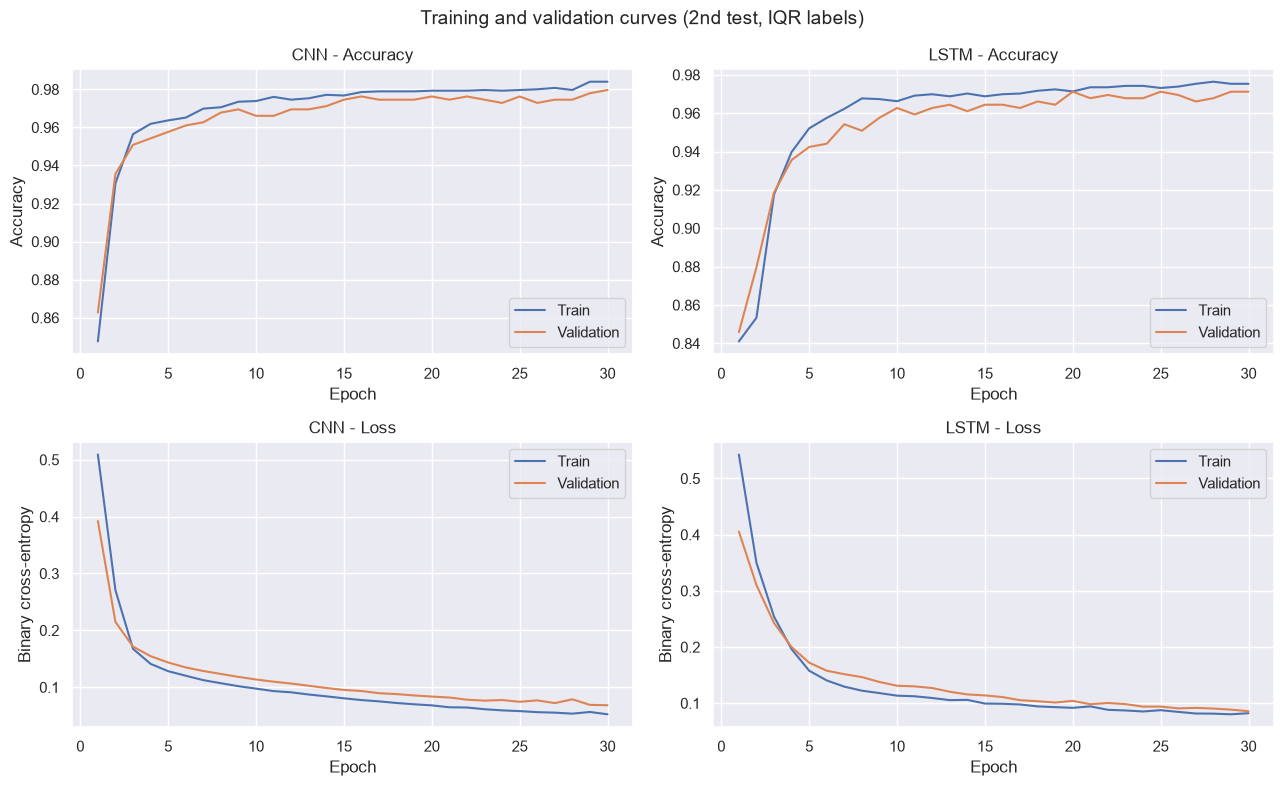

In [33]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
epochs_range = range(1, EPOCHS + 1)
for col, (name, hist) in enumerate([('CNN', cnn_history), ('LSTM', lstm_history)]):
    axes[0, col].plot(epochs_range, hist['train_acc'], label='Train')
    axes[0, col].plot(epochs_range, hist['val_acc'], label='Validation')
    axes[0, col].set_title(f'{name} - Accuracy')
    axes[0, col].set_xlabel('Epoch')
    axes[0, col].set_ylabel('Accuracy')
    axes[0, col].legend()
    axes[1, col].plot(epochs_range, hist['train_loss'], label='Train')
    axes[1, col].plot(epochs_range, hist['val_loss'], label='Validation')
    axes[1, col].set_title(f'{name} - Loss')
    axes[1, col].set_xlabel('Epoch')
    axes[1, col].set_ylabel('Binary cross-entropy')
    axes[1, col].legend()
fig.suptitle('Training and validation curves (2nd test, IQR labels)', fontsize=14)
plt.tight_layout()
plt.savefig('cnn_lstm_training_curves_2nd_test.png', dpi=150, bbox_inches='tight')
plt.show()

### 10.2 Évaluation sur le test : classification reports et matrices de confusion

=== CNN - classification report (test, 591 snapshots) ===
              precision    recall  f1-score   support

  Normal (0)     0.9823    0.9980    0.9901       500
 Anomaly (1)     0.9880    0.9011    0.9425        91

    accuracy                         0.9831       591
   macro avg     0.9851    0.9495    0.9663       591
weighted avg     0.9832    0.9831    0.9828       591



=== LSTM - classification report (test, 591 snapshots) ===
              precision    recall  f1-score   support

  Normal (0)     0.9745    0.9940    0.9842       500
 Anomaly (1)     0.9630    0.8571    0.9070        91

    accuracy                         0.9729       591
   macro avg     0.9687    0.9256    0.9456       591
weighted avg     0.9727    0.9729    0.9723       591



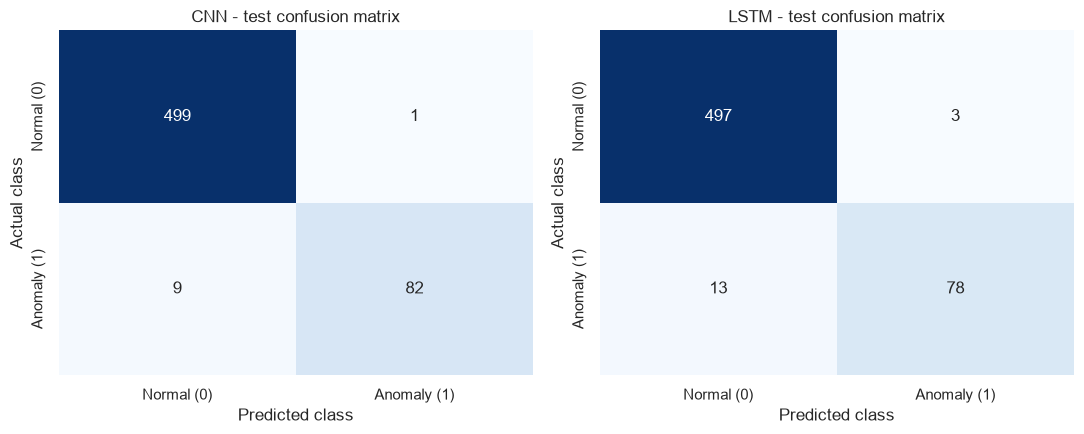

,model,train_accuracy,validation_accuracy,test_accuracy,precision,recall,f1,tn,fp,fn,tp
0,CNN,0.9840,0.9797,0.9831,0.988,0.9011,0.9425,499,1,9,82
1,LSTM,0.9753,0.9712,0.9729,0.963,0.8571,0.9070,497,3,13,78


In [34]:
def predict_dl(model, Xa, reshape):
    model.eval()
    with torch.no_grad():
        probs = model(torch.tensor(reshape(Xa))).numpy()
    return (probs >= 0.5).astype(int)

dl_records = []
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
class_labels = ['Normal (0)', 'Anomaly (1)']
for ax, (name, model, reshape, hist) in zip(axes, [
    ('CNN', cnn_model, lambda a: a.reshape(-1, 1, 2, 2), cnn_history),
    ('LSTM', lstm_model, lambda a: a.reshape(-1, 4, 1), lstm_history),
]):
    y_pred = predict_dl(model, X_test, reshape)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
    dl_records.append({
        'model': name,
        'train_accuracy': hist['train_acc'][-1],
        'validation_accuracy': hist['val_acc'][-1],
        'test_accuracy': accuracy_score(y_test, y_pred),
        'precision': precision_score(y_test, y_pred, zero_division=0),
        'recall': recall_score(y_test, y_pred, zero_division=0),
        'f1': f1_score(y_test, y_pred, zero_division=0),
        'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp),
    })
    print(f'=== {name} - classification report (test, {len(y_test)} snapshots) ===')
    print(classification_report(y_test, y_pred, target_names=class_labels, digits=4))
    sns.heatmap(
        np.array([[tn, fp], [fn, tp]]), annot=True, fmt='d', cmap='Blues', cbar=False,
        xticklabels=class_labels, yticklabels=class_labels, ax=ax,
    )
    ax.set_title(f'{name} - test confusion matrix')
    ax.set_xlabel('Predicted class')
    ax.set_ylabel('Actual class')
plt.tight_layout()
plt.savefig('cnn_lstm_confusion_matrices_2nd_test.png', dpi=150, bbox_inches='tight')
plt.show()

dl_metrics = pd.DataFrame(dl_records)
dl_metrics.to_csv('cnn_lstm_metrics_2nd_test.csv', index=False)
display(dl_metrics.round(4))

**Résultat test** : CNN accuracy 98,31 % / F1 0,9425 (9 anomalies ratées sur 91) ;
LSTM accuracy 97,29 % / F1 0,9070 (13 ratées sur 91). L'article publie des accuracies
validation de 99,28 % pour les deux : non reproduites exactement (architecture exacte,
split et framework non spécifiés / différents).

## 11. Sélection du meilleur modèle et conclusions

Récapitulatif de tous les modèles évalués. Attention : les modèles classiques sont
évalués en 5-fold out-of-fold (3 936 snapshots) et les modèles deep learning sur le
split test (591 snapshots) ; les protocoles diffèrent légèrement, mais le classement
est sans ambiguïté.

In [35]:
recap_classical = pd.read_csv('requested5_models_oof_metrics_2nd_test.csv')
recap_classical = recap_classical.loc[recap_classical['scope'].eq('Overall'),
                                    ['model', 'accuracy', 'precision', 'recall', 'f1']].copy()
recap_classical['protocole'] = 'CV 5-fold (out-of-fold)'

recap_dl = pd.read_csv('cnn_lstm_metrics_2nd_test.csv')[['model', 'test_accuracy', 'precision', 'recall', 'f1']]
recap_dl = recap_dl.rename(columns={'test_accuracy': 'accuracy'})
recap_dl['protocole'] = 'Test (split 70/15/15)'

recap = (pd.concat([recap_classical, recap_dl], ignore_index=True)
         .sort_values('f1', ascending=False)
         .reset_index(drop=True))
display(recap.round(4))
recap.to_csv('recapitulatif_modeles_2nd_test.csv', index=False)

best = recap.iloc[0]
print(f"Meilleur modèle : {best['model']} — F1 = {best['f1']:.4f}, accuracy = {best['accuracy']:.4f}")

,model,accuracy,precision,recall,f1,protocole
0,Decision Tree,0.9970,0.9901,0.9901,0.9901,CV 5-fold (out-of-fold)
1,Random Forest,0.9964,0.9966,0.9802,0.9884,CV 5-fold (out-of-fold)
2,KNN,0.9947,0.9949,0.9703,0.9825,CV 5-fold (out-of-fold)
3,SVM (RBF),0.9883,0.9361,0.9917,0.9631,CV 5-fold (out-of-fold)
4,CNN,0.9831,0.9880,0.9011,0.9425,Test (split 70/15/15)
5,Logistic Regression,0.9787,0.9117,0.9538,0.9323,CV 5-fold (out-of-fold)
6,LSTM,0.9729,0.9630,0.8571,0.9070,Test (split 70/15/15)


Meilleur modèle : Decision Tree — F1 = 0.9901, accuracy = 0.9970


### Conclusions

1. **Meilleur modèle : l'arbre de décision (Decision Tree)** — F1 = 0,9901,
   accuracy = 0,9970, seulement 6 FP + 6 FN sur 3 936 snapshots. Le modèle simple
   suffit, conformément à l'argument de l'article ; le deep learning (CNN 0,9425,
   LSTM 0,9070) n'apporte aucun gain sur ces 4 attributs.
2. **Bearing 1** concentre les anomalies (21,1 % des snapshots, vibration max 0,453,
   variance ~12–18× les autres) — cohérent avec la vérité terrain : défaillance de
   la bague extérieure du Bearing 1 uniquement.
3. **Limites** : les labels IQR sont statistiques et dérivés des 4 mêmes attributs
   que ceux utilisés pour la classification → scores optimistes ; le split aléatoire
   de snapshots temporels introduit en plus une optimisme temporel. Ces résultats
   valident le pipeline, pas la détection de panne en conditions réelles.
4. Les « fréquences pics » FFT à 20,33 Hz sur la table de trend sont un artefact de
   l'article ; l'analyse physique correcte se fait intra-fichier à 20 kHz.

## 12. Inventaire des fichiers produits

Tous les fichiers sont écrits dans le dossier du notebook (`2nd_test`).

In [36]:
produced_files = [
    'merged_Dataset_BearingTest_2.csv',
    'bearing_features_labels_2nd_test.csv',
    'iqr_thresholds_2nd_test.csv',
    'class_distribution_2nd_test.csv',
    'classical_model_cv_results_2nd_test.csv',
    'classical_model_cv_summary_2nd_test.csv',
    'selected_model_test_metrics_2nd_test.csv',
    'selected_model_confusion_matrices_2nd_test.png',
    'selected_model_confusion_matrices_by_bearing_2nd_test.png',
    'requested5_models_oof_metrics_2nd_test.csv',
    'requested5_confusion_matrices_2nd_test.png',
    'requested5_confusion_matrices_by_bearing_2nd_test.png',
    'cnn_lstm_training_curves_2nd_test.png',
    'cnn_lstm_confusion_matrices_2nd_test.png',
    'cnn_lstm_metrics_2nd_test.csv',
    'recapitulatif_modeles_2nd_test.csv',
    'all_2nd_test_train_b3_1st_test_features.csv',
    'all_2nd_test_train_b3_1st_test_metrics.csv',
    'all_2nd_test_train_b3_1st_test_predictions.csv',
    'bearing1_failure_timeline_alerts_2nd_test.csv',
    'bearing1_failure_timeline_metrics_2nd_test.csv',
]
inventory = pd.DataFrame([
    {'fichier': f, 'taille_ko': round(os.path.getsize(f) / 1024, 1)}
    for f in produced_files if os.path.exists(f)
])
display(inventory)
print(f'{len(inventory)} fichiers produits.')

,fichier,taille_ko
0,merged_Dataset_BearingTest_2.csv,97.0
1,bearing_features_labels_2nd_test.csv,478.1
2,iqr_thresholds_2nd_test.csv,1.8
3,class_distribution_2nd_test.csv,0.2
4,classical_model_cv_results_2nd_test.csv,6.0
5,classical_model_cv_summary_2nd_test.csv,0.8
6,selected_model_test_metrics_2nd_test.csv,2.2
7,selected_model_confusion_matrices_2nd_test.png,114.1
8,selected_model_confusion_matrices_by_bearing_2...,386.7
9,requested5_models_oof_metrics_2nd_test.csv,2.6


16 fichiers produits.
